## Injection tests of the location decoders
Planted-change checks of the sliding LDA and of the masked LaBraM decoder, moved from `LDA.ipynb`. The setup cells
below are copies of the `LDA.ipynb` helpers these tests use (filters, loaders, topomaps, Task B contrasts) and the
accuracy window of the real data, chosen the same way.

In [16]:
import os
from pathlib import Path

import numpy as np
import pandas as pd

from core import settings, plot_data_processing, plotting
from core import io
from core.decoding.data import band_file_name

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir('..')

run_lda = False
stats_dir = settings.BASE_DIR / "outputs" / "decoding_inj_outputs"
# folders of the figures' save buttons, one per test
plot_root = settings.PLOT_DIR / "decoding_inj"
plot_dirs = {"lda": plot_root / "lda",  # pseudo-session searchlight maps, one subfolder per injection_prefix (pooled / per subject)
             "labram_same_trials": plot_root / "labram" / "fixed_session" / "same_trials",  # fixed model, trials uninjected vs injected
             "labram_split": plot_root / "labram" / "fixed_session" / "a_b_split",  # fixed model, half A uninjected vs half B
             "labram_within": plot_root / "labram" / "within_session"}  # pseudo pre model vs pseudo post models

In [17]:
from core import utils

# filters of the analysis, as in plasticity_plotting.ipynb. They select the trials loaded from the saved outputs only
subjects = None  # set to None to load all subjects
conditions = None  # set to None to load all location conditions; with a subset, the per-class AUCs of the missing classes can't be computed
id_low, id_high = None, None
trial_ids = [i for i in range(id_low, id_high)] if id_low is not None and id_high is not None else None  # set to None to load all trial ids
exclude_left_patched = True
exclude_right_patched_lefties = True  # set to True to exclude subjects with left eye dominance and right patching
exclude_button_press = False  # set to True to exclude button press trials (everything before STMD59)

# select subjects to exclude based on eye dominance, button press, and patching side
exclude_subjects = list(settings.EXCLUDED_SUBJECTS)
if exclude_left_patched:
    exclude_subjects.extend(utils.get_subjects_by_eye_dominance("left", settings.DATA_ROOT / "eye_dominance.csv"))
if exclude_right_patched_lefties:
    exclude_subjects.extend(utils.get_subjects_by_eye_dominance("left", settings.DATA_ROOT / "rightpatch_eye_dominance.csv"))  # after STMD35, all patches were on the right eye, so exclude lefties
if exclude_button_press:
    press_subjects = [subj for subj in io.get_stored_subject_names(settings.DATA_ROOT) if utils.subject_paradigm(subj, settings.NO_PRESS_FROM_SUBJECT) == "press"]
    exclude_subjects.extend(press_subjects)

In [18]:
# load the saved data
CH_NAMES = [name.replace("EEG ", "").replace("-REF", "") for name in settings.CHORDER_STANDARD]  # e.g. FP1, in the channel order of the outputs


def load_filtered_merged(model_name, mode="trial", ch_names=CH_NAMES, sessions=("baseline", "postpatch")):
    """
    The trial table (class_trials_frame) or, with mode="channel", the channel table (class_channels_frame) of the given
    sessions of a class run, all folds, with the filters above. A run trained on post-patching data has post-patching
    outputs only, sessions=("postpatch",).
    """
    run_dir = settings.INFERENCE_DIR / model_name
    folds = sorted(int(d.name) for d in run_dir.iterdir() if d.is_dir() and d.name.isdigit())
    frames = []
    for session in sessions:
        merged = []
        for i in folds:
            file_path = settings.INFERENCE_DIR / model_name / str(i) / f"{session}_reconstruction.h5"
            merged.extend(io.load_inference_trials(file_path, subjects=subjects, conditions=conditions, idxs=trial_ids, exclude_subjects=exclude_subjects, window="full", stim_patch=None))
        if mode == "channel":
            frames.append(plot_data_processing.class_channels_frame(merged, model_name, session=session, ch_names=ch_names))
        else:
            frames.append(plot_data_processing.class_trials_frame(merged, model_name, session=session))
    return pd.concat(frames, ignore_index=True)

In [19]:
import matplotlib.pyplot as plt
import mne
import textwrap

topo_info = plot_data_processing.create_topomap_info()  # 10-20 labels at the HydroCel positions, in CH_NAMES order

def channel_change_topomaps(df, label, value="occlusion_effect", relative=False, model_label="masked LaBraM decoder",
                            save_dir=None, default_name="untitled", session_labels=("baseline", "post-patching"), change_label=None):
    """
    Topomaps of a per-channel column of a channel table (class_channels_frame): the subject means of its two sessions
    ("baseline" and "postpatch" in the table, titled session_labels, e.g. ("uninjected", "injected") for an injection
    test), the mean change (second - first, titled change_label, e.g. "change (B - A)" for halves A and B, default
    "change (second - first)") and its d_z over the subjects with both. The two session maps and the change
    share one symmetric colour scale, so a change is seen at the size of the maps it comes from; d_z has its own scale.
    NaN (interpolated) rows are left out of the subject means. Prints the 3 channels with the largest and the 3 with the
    smallest change. save_dir: folder of the figure's save button (none without it), default_name its file name.
    relative (occlusion only): the subject's mean drop divided by its mean true-class probability without hiding, per
    session and channel (a ratio of means: per-trial ratios explode for trials with a true-class probability near 0).
    """
    first, second = session_labels
    change_title = change_label or f"change ({second} - {first})"
    grouped = df.groupby(["session", "subject", "channel"])
    subject_means = grouped[value].mean()
    if relative:
        subject_means = subject_means / grouped["p_true"].mean()  # p_true is NaN on the same (interpolated) rows
    subject_means = subject_means.unstack("channel")[CH_NAMES]
    baseline, postpatch = subject_means.loc["baseline"], subject_means.loc["postpatch"]
    subjects = baseline.index.intersection(postpatch.index)
    change = postpatch.loc[subjects] - baseline.loc[subjects]
    maps = {first: baseline.loc[subjects].mean(), second: postpatch.loc[subjects].mean(),
            change_title: change.mean(), "d_z of the change": change.mean() / change.std(ddof=1)}
    shared_lim = pd.concat([maps[first], maps[second], maps[change_title]]).abs().max()

    fig, axes = plt.subplots(1, len(maps), figsize=(5 * len(maps), 4.5))
    for ax, (title, values) in zip(axes, maps.items()):
        lim = values.abs().max() if title == "d_z of the change" else shared_lim
        values = values.to_numpy(dtype=float)
        keep = np.flatnonzero(np.isfinite(values))
        im, _ = mne.viz.plot_topomap(values[keep], mne.pick_info(topo_info, keep), axes=ax, show=False, vlim=(-lim, lim), cmap="RdBu_r")
        ax.set_title(title)
        fig.colorbar(im, ax=ax, shrink=0.7)
    # long titles over several lines (at most about 8 characters per inch of figure width), growing upwards above the panels
    title = textwrap.fill(f"{label}, {model_label} (N={len(subjects)} subjects)", width=int(8 * fig.get_figwidth()))
    fig.suptitle(title, y=1.0, va="bottom")
    plt.show()
    if save_dir is not None:
        plotting.save_button(fig, save_dir=save_dir, default_name=default_name)

    ordered = maps[change_title].dropna().sort_values()
    print(f"{label}, {change_title}:")
    print("  max: " + ", ".join(f"{ch} {v:+.4f}" for ch, v in ordered[::-1][:3].items()))
    print("  min: " + ", ".join(f"{ch} {v:+.4f}" for ch, v in ordered[:3].items()))

In [20]:
import h5py
import matplotlib.pyplot as plt
from core.decoding import metrics as decoding_metrics

sliding_name = "sliding_lda"  # output folder of decoding/run_sliding_lda.py
n_permutations = 5000


def load_time_metrics(name, file_suffix="reconstruction"):
    """
    Per-subject time metrics (decoding_metrics.time_metrics_frame) of both sessions of a sliding decoder, with the filters
    above, from its {session}_{file_suffix}.h5 files ("searchlight": the searchlight outputs, one set per channel).
    """
    run_dir = settings.INFERENCE_DIR / name
    folds = sorted(int(d.name) for d in run_dir.iterdir() if d.is_dir() and d.name.isdigit())
    frames = []
    for session in ("baseline", "postpatch"):
        trials = []
        for k in folds:
            path = run_dir / str(k) / f"{session}_{file_suffix}.h5"
            with h5py.File(path, "r") as f:
                set_names, times = [str(s) for s in f.attrs["sets"]], np.asarray(f.attrs["times"])
            trials.extend(io.load_inference_trials(path, subjects=subjects, conditions=conditions, idxs=trial_ids,
                                                   exclude_subjects=exclude_subjects, stim_patch=None))
        frames.append(decoding_metrics.time_metrics_frame(trials, name, session, set_names, times, settings.N_LOCATION_CLASSES))
    return pd.concat(frames, ignore_index=True), set_names, times

In [21]:
def q4_contrasts(time_df, accuracy_window, set_name):
    """
    The Task B contrast table of a time table (load_time_metrics): per-subject one-vs-rest AUC curves of set_name, the
    classes as side slots relative to the patched eye (subjects with both sessions and a known patched eye), accuracy =
    mean AUC in accuracy_window, latency = fractional area latency of the smoothed mean curves (jackknife), Holm-corrected
    per kind. Returns (contrast table, Q4 subjects).
    """
    auc_df = time_df[(time_df["metric"] == "auc") & (time_df["set"] == set_name)]

    def class_curves(session):  # {subject: (n_classes, n_times)}
        table = auc_df[auc_df["session"] == session].pivot_table(index=["subject", "class"], columns="time", values="value")
        return {s: table.loc[s].reindex(range(settings.N_LOCATION_CLASSES)).to_numpy() for s in table.index.get_level_values(0).unique()}

    baseline_curves, postpatch_curves = class_curves("baseline"), class_curves("postpatch")
    both = sorted(set(baseline_curves) & set(postpatch_curves))
    baseline_slots, q4_subjects = decoding_metrics.side_slots(np.stack([baseline_curves[s] for s in both]), both, eyes, settings.LOCATION_CLASSES)
    postpatch_slots, _ = decoding_metrics.side_slots(np.stack([postpatch_curves[s] for s in both]), both, eyes, settings.LOCATION_CLASSES)
    curve_times = np.asarray(auc_df["time"].drop_duplicates().sort_values())

    # accuracy: mean AUC in the window; latency: smoothed curves, fractional area latency on the mean curves (jackknife)
    in_window = (curve_times >= accuracy_window[0] - 1e-9) & (curve_times <= accuracy_window[1] + 1e-9)
    accuracy = decoding_metrics.accuracy_contrasts(baseline_slots[..., in_window].mean(-1), postpatch_slots[..., in_window].mean(-1))
    smoothing = round(settings.Q4_LATENCY_SMOOTHING / (curve_times[1] - curve_times[0]))
    latency = decoding_metrics.latency_contrasts(curve_times, decoding_metrics.smooth(baseline_slots, smoothing),
                                                 decoding_metrics.smooth(postpatch_slots, smoothing), 0.5,
                                                 settings.Q4_AREA_FRACTION, settings.Q4_LATENCY_SEARCH, settings.Q4_AREA_FLOOR)
    q4 = pd.concat([accuracy, latency], ignore_index=True)
    for kind in ("change", "baseline only"):
        q4.loc[q4["kind"] == kind, "p_holm"] = decoding_metrics.holm(q4.loc[q4["kind"] == kind, "p"])
    return q4, q4_subjects


eyes = decoding_metrics.patched_eyes(settings.DATA_ROOT / "eye_dominance.csv", settings.DATA_ROOT / "rightpatch_eye_dominance.csv")

In [22]:
# the real data's sliding LDA outputs, only for the accuracy window, chosen as in LDA.ipynb (Task B, B1)
time_df, set_names, times = load_time_metrics(sliding_name)
primary_set = set_names[0]

auc_df = time_df[(time_df["metric"] == "auc") & (time_df["set"] == primary_set)]

# B1: the accuracy window, from the baseline grand average over all classes only
if settings.Q4_ACCURACY_WINDOW is None:
    grand = auc_df[auc_df["session"] == "baseline"].groupby(["subject", "time"])["value"].mean().unstack("time")
    found = [c for c in decoding_metrics.cluster_test_vs_chance(grand.to_numpy(), 0.5, n_permutations, settings.SEED) if c[2] < 0.05]
    if not found:
        raise ValueError("No baseline cluster above chance, the accuracy window can't be chosen")
    first, last, p = max(found, key=lambda c: c[1] - c[0])
    accuracy_window = (round(float(grand.columns[first]), 3), round(float(grand.columns[last]), 3))
    print(f"Suggested Q4_ACCURACY_WINDOW = {accuracy_window} (baseline cluster p = {p:.4f}); write it into settings before looking at post data")
else:
    accuracy_window = settings.Q4_ACCURACY_WINDOW
print(f"Accuracy window: {accuracy_window} s")

Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading in

## Injection tests
Planted-change checks of the sliding LDA (handoff C2-C4), on the runs of `decoding/run_lda_injection.py`: baseline
trials split into two pseudo-sessions, pseudo pre saved as baseline and pseudo post as post-patching, with a change
planted into the pseudo post trials of one condition per run. Every run is analysed like the real data (Task B, the
accuracy window fixed above). "Side" is the side of the stimulus location: with right-patched subjects, the right
locations are the patched side, so patched - other at mid = change of R_mid - change of L_mid.
- **Null** (C2): no change contrast may be significant after Holm correction.
- **Delay** (C3, `d` s later): the planted class's latency rises by about `d` (`planted class Δ latency`, jackknife), and
  the latency contrast at its eccentricity recovers it: about +d for a patched-side class, -d for the other side.
- **Attenuation** (C4, `a` x the class-average evoked response removed at the posterior channels, 0-0.5 s): the planted
  class's AUC in the window drops (`planted class Δ AUC`), and the accuracy contrast at its eccentricity detects it:
  < 0 for a patched-side class, > 0 for the other side. With searchlight outputs, the planted class's AUC change
  should be negative at the posterior clusters. A decoder retrained on the planted pseudo post can learn the weakened
  class as a new pattern, so this plant may go undetected.
- **Class-specific attenuation** (`classattenuation`, `--class_specific`): as the attenuation, but only the class's
  deviation from the mean over the 8 locations is removed (`a` = 1: no posterior location-specific average left), which a
  retrained decoder can't recover from. Expected as for the attenuation.


Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Null run, split 0: significant change contrasts after Holm: 0 of 10


,contrast,measure,ecc,kind,estimate,se,t,df,p,p_wilcoxon,n,p_holm
0,patched - other,accuracy,near,change,0.0399,0.0196,2.0389,44,0.0475,0.0516,45,0.4275
1,patched - other,accuracy,near,baseline only,-0.0147,0.0130,-1.1283,44,0.2653,0.3641,45,1.0000
2,patched - other,accuracy,mid,change,0.0202,0.0160,1.2678,44,0.2115,0.4136,45,1.0000
3,patched - other,accuracy,mid,baseline only,-0.0016,0.0145,-0.1084,44,0.9141,0.7122,45,1.0000
4,patched - other,accuracy,far,change,0.0083,0.0179,0.4633,44,0.6455,0.3129,45,1.0000
5,patched - other,accuracy,far,baseline only,0.0041,0.0134,0.3062,44,0.7609,0.8933,45,1.0000
6,top - sides,accuracy,near,change,0.0019,0.0147,0.1260,44,0.9003,0.9465,45,1.0000
7,top - sides,accuracy,near,baseline only,-0.0075,0.0124,-0.6052,44,0.5482,0.6709,45,1.0000
8,top - sides,accuracy,mid,change,-0.0046,0.0165,-0.2769,44,0.7832,0.7122,45,1.0000
9,top - sides,accuracy,mid,baseline only,-0.0261,0.0121,-2.1522,44,0.0369,0.0284,45,0.3690


Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Null run, split 1: significant change contrasts after Holm: 0 of 10


,contrast,measure,ecc,kind,estimate,se,t,df,p,p_wilcoxon,n,p_holm
0,patched - other,accuracy,near,change,0.0017,0.0220,0.0755,44,0.9402,0.9376,45,1.0000
1,patched - other,accuracy,near,baseline only,-0.0080,0.0140,-0.5708,44,0.5710,0.7205,45,1.0000
2,patched - other,accuracy,mid,change,0.0117,0.0163,0.7155,44,0.4781,0.4266,45,1.0000
3,patched - other,accuracy,mid,baseline only,0.0003,0.0131,0.0201,44,0.9841,0.8669,45,1.0000
4,patched - other,accuracy,far,change,-0.0162,0.0167,-0.9720,44,0.3364,0.3350,45,1.0000
5,patched - other,accuracy,far,baseline only,0.0148,0.0120,1.2324,44,0.2244,0.1810,45,1.0000
6,top - sides,accuracy,near,change,-0.0119,0.0163,-0.7298,44,0.4694,0.3407,45,1.0000
7,top - sides,accuracy,near,baseline only,0.0041,0.0115,0.3521,44,0.7264,0.6791,45,1.0000
8,top - sides,accuracy,mid,change,-0.0146,0.0173,-0.8444,44,0.4030,0.3183,45,1.0000
9,top - sides,accuracy,mid,baseline only,-0.0137,0.0130,-1.0577,44,0.2960,0.3700,45,1.0000


Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Null run, split 2: significant change contrasts after Holm: 1 of 10


,contrast,measure,ecc,kind,estimate,se,t,df,p,p_wilcoxon,n,p_holm
0,patched - other,accuracy,near,change,0.0088,0.0172,0.5128,44,0.6106,0.6628,45,1.0000
1,patched - other,accuracy,near,baseline only,0.0027,0.0126,0.2130,44,0.8323,0.8669,45,1.0000
2,patched - other,accuracy,mid,change,0.0018,0.0203,0.0864,44,0.9315,0.7885,45,1.0000
3,patched - other,accuracy,mid,baseline only,0.0061,0.0141,0.4344,44,0.6661,0.8406,45,1.0000
4,patched - other,accuracy,far,change,-0.0064,0.0176,-0.3631,44,0.7182,0.7122,45,1.0000
5,patched - other,accuracy,far,baseline only,0.0060,0.0148,0.4036,44,0.6885,0.8757,45,1.0000
6,top - sides,accuracy,near,change,0.0149,0.0162,0.9195,44,0.3628,0.4532,45,1.0000
7,top - sides,accuracy,near,baseline only,-0.0168,0.0130,-1.2956,44,0.2019,0.2252,45,1.0000
8,top - sides,accuracy,mid,change,-0.0065,0.0180,-0.3645,44,0.7172,0.7205,45,1.0000
9,top - sides,accuracy,mid,baseline only,-0.0034,0.0146,-0.2343,44,0.8159,0.7885,45,1.0000


Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading in

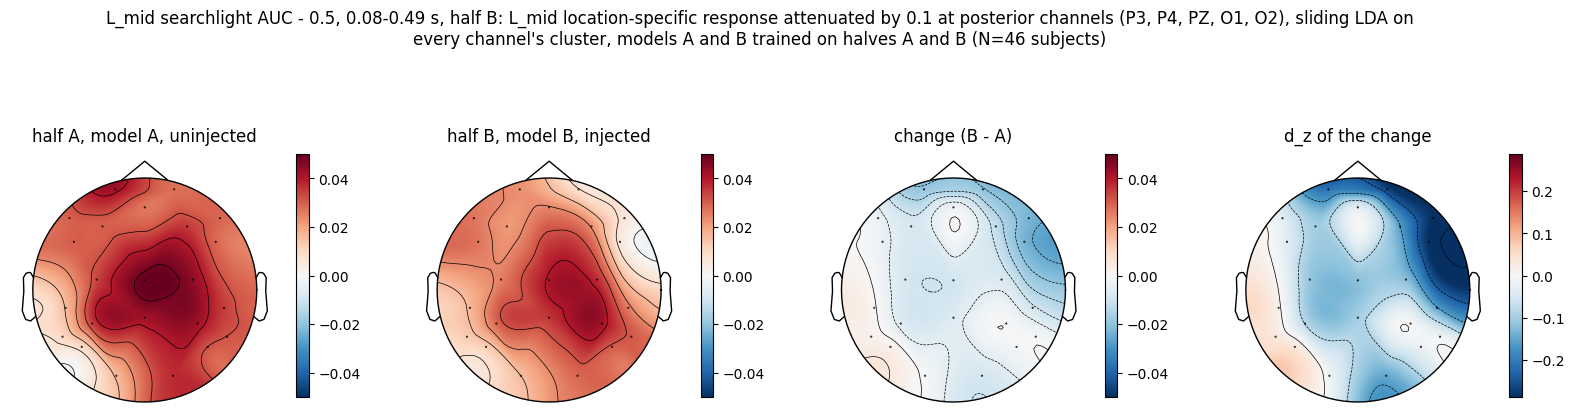

L_mid searchlight AUC - 0.5, 0.08-0.49 s, half B: L_mid location-specific response attenuated by 0.1 at posterior channels (P3, P4, PZ, O1, O2), change (B - A):
  max: A1 +0.0022, T5 +0.0022, T3 +0.0005
  min: F8 -0.0229, T2 -0.0229, FP2 -0.0194
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filterin

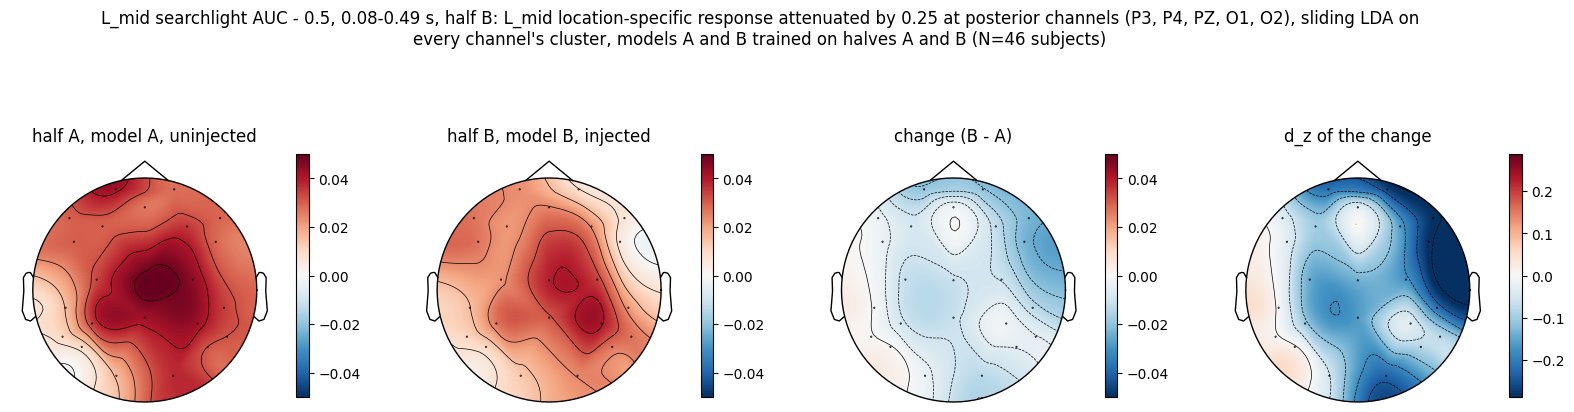

L_mid searchlight AUC - 0.5, 0.08-0.49 s, half B: L_mid location-specific response attenuated by 0.25 at posterior channels (P3, P4, PZ, O1, O2), change (B - A):
  max: A1 +0.0004, T5 +0.0004, T3 -0.0006
  min: F8 -0.0229, T2 -0.0229, FP2 -0.0194
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filteri

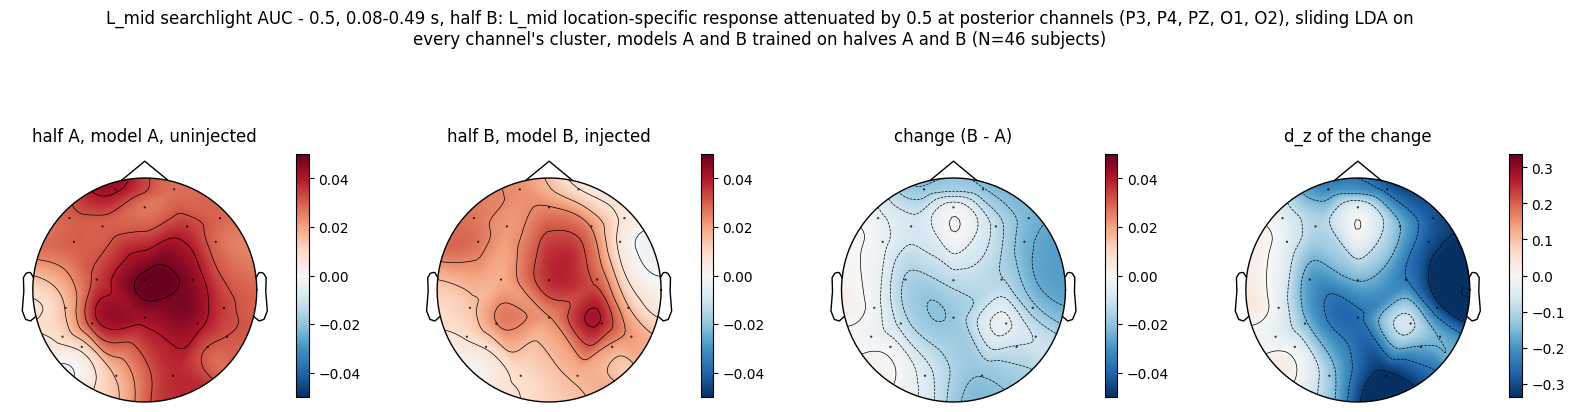

L_mid searchlight AUC - 0.5, 0.08-0.49 s, half B: L_mid location-specific response attenuated by 0.5 at posterior channels (P3, P4, PZ, O1, O2), change (B - A):
  max: T5 -0.0020, A1 -0.0020, FZ -0.0021
  min: F8 -0.0229, T2 -0.0229, O2 -0.0198
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering

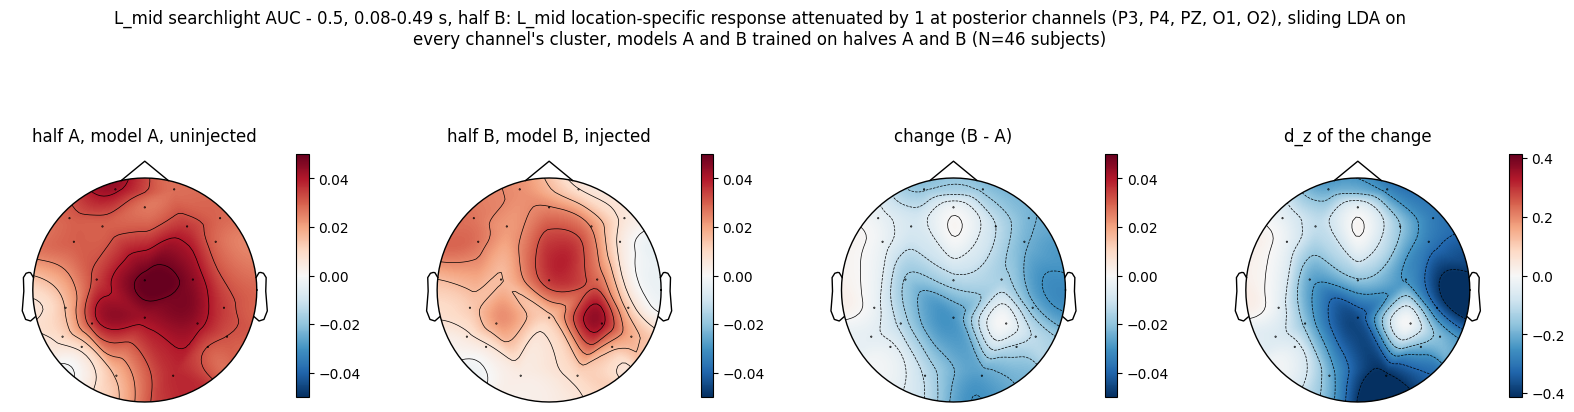

L_mid searchlight AUC - 0.5, 0.08-0.49 s, half B: L_mid location-specific response attenuated by 1 at posterior channels (P3, P4, PZ, O1, O2), change (B - A):
  max: P4 -0.0008, FZ -0.0021, T3 -0.0033
  min: PZ -0.0287, O2 -0.0270, F8 -0.0229
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering f

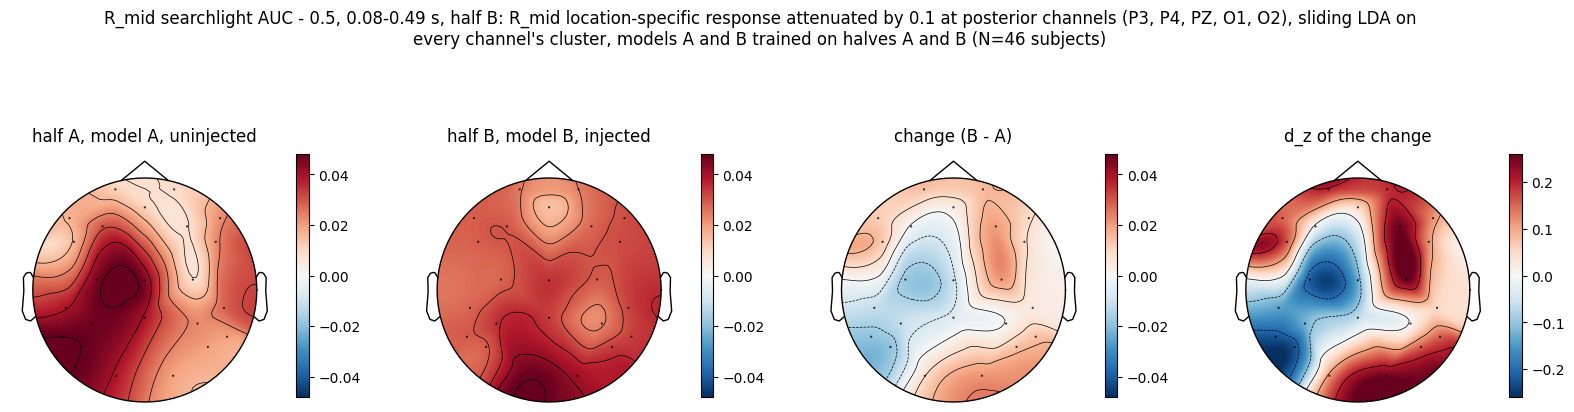

R_mid searchlight AUC - 0.5, 0.08-0.49 s, half B: R_mid location-specific response attenuated by 0.1 at posterior channels (P3, P4, PZ, O1, O2), change (B - A):
  max: O2 +0.0207, C4 +0.0206, F4 +0.0200
  min: A1 -0.0187, T5 -0.0187, C3 -0.0177
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering

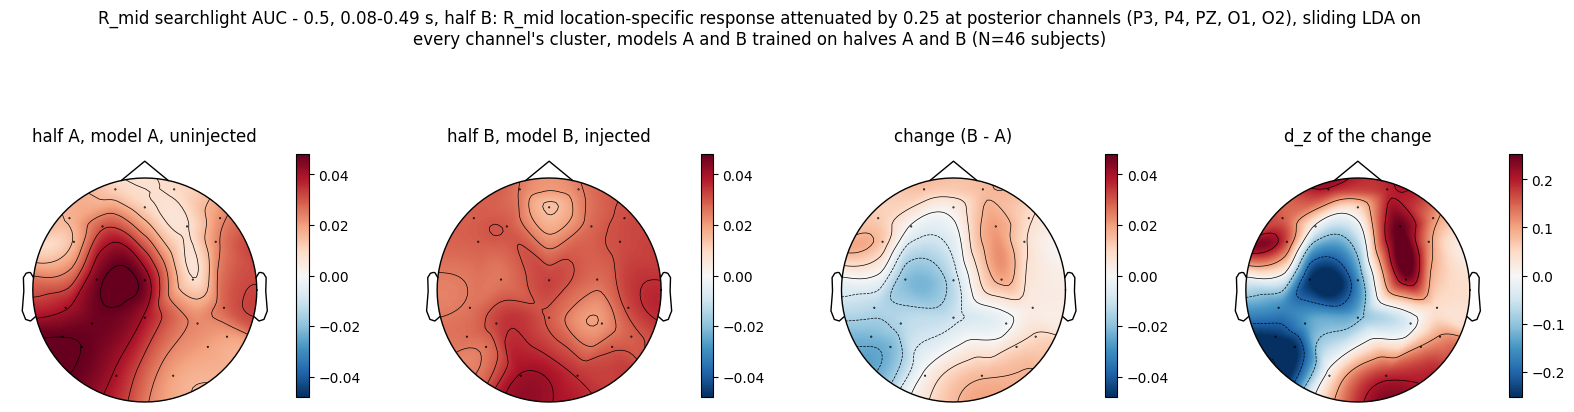

R_mid searchlight AUC - 0.5, 0.08-0.49 s, half B: R_mid location-specific response attenuated by 0.25 at posterior channels (P3, P4, PZ, O1, O2), change (B - A):
  max: F4 +0.0200, C4 +0.0184, O2 +0.0151
  min: A1 -0.0215, T5 -0.0215, C3 -0.0200
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filterin

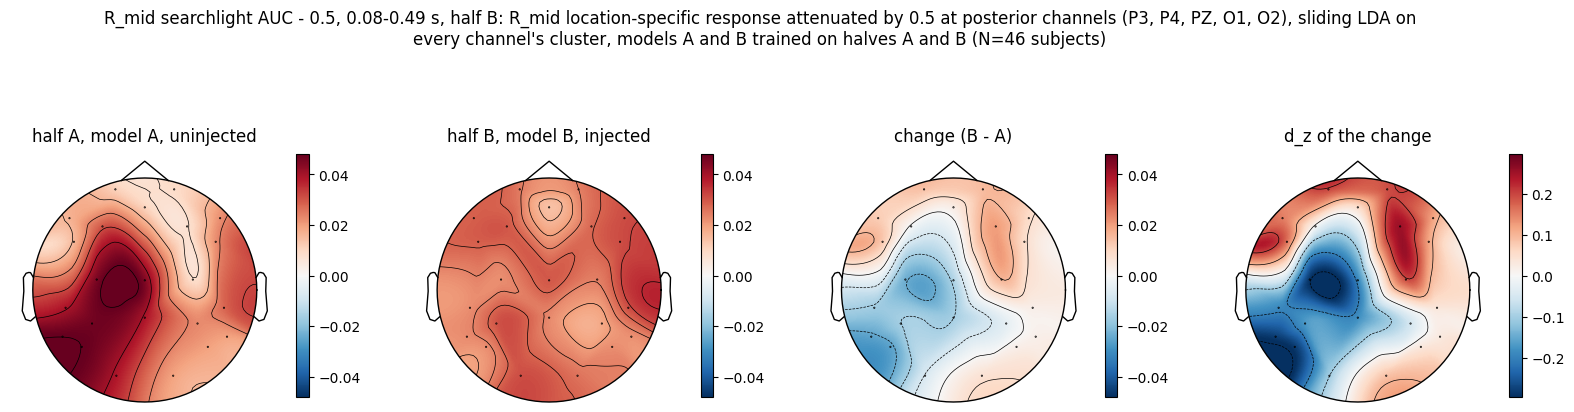

R_mid searchlight AUC - 0.5, 0.08-0.49 s, half B: R_mid location-specific response attenuated by 0.5 at posterior channels (P3, P4, PZ, O1, O2), change (B - A):
  max: F4 +0.0200, C4 +0.0159, FP2 +0.0150
  min: A1 -0.0252, T5 -0.0252, C3 -0.0233
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filterin

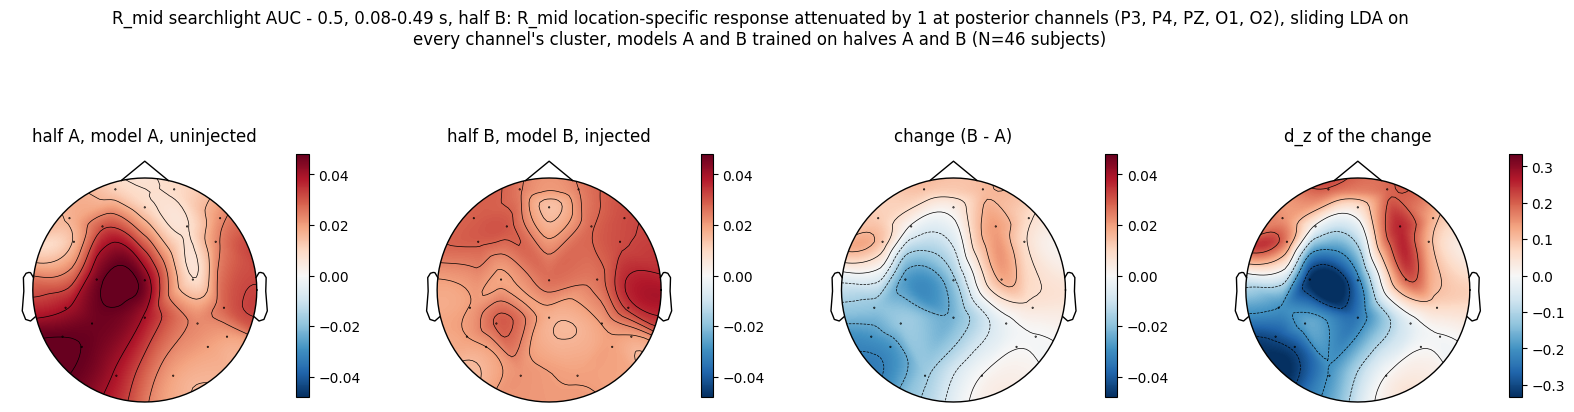

R_mid searchlight AUC - 0.5, 0.08-0.49 s, half B: R_mid location-specific response attenuated by 1 at posterior channels (P3, P4, PZ, O1, O2), change (B - A):
  max: F4 +0.0200, C4 +0.0176, FP2 +0.0150
  min: A1 -0.0280, T5 -0.0280, C3 -0.0267


,type,class,size,measure,expected,estimate,se,t,p,n,p_holm
25,classattenuation,L_mid,0.10,patched - other accuracy,> 0,0.0222,0.0159,1.3970,0.1694,45.0,1.0000
27,classattenuation,L_mid,0.25,patched - other accuracy,> 0,0.0247,0.0158,1.5606,0.1258,45.0,1.0000
29,classattenuation,L_mid,0.50,patched - other accuracy,> 0,0.0267,0.0157,1.6941,0.0973,45.0,0.7786
31,classattenuation,L_mid,1.00,patched - other accuracy,> 0,0.0214,0.0160,1.3410,0.1868,45.0,1.0000
24,classattenuation,L_mid,0.10,planted class Δ AUC,< 0,-0.0163,0.0103,-1.5895,0.1190,46.0,NaN
26,classattenuation,L_mid,0.25,planted class Δ AUC,< 0,-0.0185,0.0104,-1.7812,0.0816,46.0,NaN
28,classattenuation,L_mid,0.50,planted class Δ AUC,< 0,-0.0203,0.0105,-1.9329,0.0596,46.0,NaN
30,classattenuation,L_mid,1.00,planted class Δ AUC,< 0,-0.0146,0.0105,-1.3861,0.1725,46.0,NaN
33,classattenuation,R_mid,0.10,patched - other accuracy,< 0,0.0178,0.0161,1.1021,0.2764,45.0,1.0000
35,classattenuation,R_mid,0.25,patched - other accuracy,< 0,0.0145,0.0163,0.8872,0.3798,45.0,1.0000


Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading in

,type,class,size,measure,expected,estimate,se,t,p,n,p_holm
13,classattenuation,L_mid,0.10,patched - other accuracy,> 0,0.0145,0.0160,0.9048,0.3705,45.0,1.0000
15,classattenuation,L_mid,0.25,patched - other accuracy,> 0,0.0182,0.0156,1.1638,0.2508,45.0,1.0000
17,classattenuation,L_mid,0.50,patched - other accuracy,> 0,0.0218,0.0151,1.4422,0.1563,45.0,1.0000
19,classattenuation,L_mid,1.00,patched - other accuracy,> 0,0.0158,0.0153,1.0313,0.3080,45.0,1.0000
12,classattenuation,L_mid,0.10,planted class Δ AUC,< 0,-0.0017,0.0117,-0.1419,0.8878,46.0,NaN
14,classattenuation,L_mid,0.25,planted class Δ AUC,< 0,-0.0055,0.0115,-0.4824,0.6319,46.0,NaN
16,classattenuation,L_mid,0.50,planted class Δ AUC,< 0,-0.0092,0.0112,-0.8243,0.4141,46.0,NaN
18,classattenuation,L_mid,1.00,planted class Δ AUC,< 0,-0.0033,0.0115,-0.2878,0.7748,46.0,NaN
21,classattenuation,R_mid,0.10,patched - other accuracy,< 0,0.0100,0.0165,0.6056,0.5479,45.0,1.0000
23,classattenuation,R_mid,0.25,patched - other accuracy,< 0,0.0082,0.0167,0.4903,0.6263,45.0,1.0000


Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading in

,type,class,size,measure,expected,estimate,se,t,p,n,p_holm
13,classattenuation,L_mid,0.10,patched - other accuracy,> 0,0.0044,0.0203,0.2180,0.8284,45.0,1.0000
15,classattenuation,L_mid,0.25,patched - other accuracy,> 0,0.0078,0.0202,0.3866,0.7009,45.0,1.0000
17,classattenuation,L_mid,0.50,patched - other accuracy,> 0,0.0119,0.0201,0.5939,0.5556,45.0,1.0000
19,classattenuation,L_mid,1.00,patched - other accuracy,> 0,0.0082,0.0194,0.4234,0.6741,45.0,1.0000
12,classattenuation,L_mid,0.10,planted class Δ AUC,< 0,-0.0046,0.0138,-0.3319,0.7415,46.0,NaN
14,classattenuation,L_mid,0.25,planted class Δ AUC,< 0,-0.0082,0.0138,-0.5975,0.5532,46.0,NaN
16,classattenuation,L_mid,0.50,planted class Δ AUC,< 0,-0.0126,0.0138,-0.9156,0.3647,46.0,NaN
18,classattenuation,L_mid,1.00,planted class Δ AUC,< 0,-0.0094,0.0134,-0.7048,0.4846,46.0,NaN
21,classattenuation,R_mid,0.10,patched - other accuracy,< 0,-0.0000,0.0203,-0.0019,0.9985,45.0,1.0000
23,classattenuation,R_mid,0.25,patched - other accuracy,< 0,-0.0015,0.0204,-0.0712,0.9435,45.0,1.0000


In [23]:
from scipy.stats import ttest_1samp

injection_prefix = "lda_injection"
split_seeds = [0, 1, 2]
null_split_seeds = [0, 1, 2]


def side_subject_values(time_df, set_name):
    """
    Per-subject values of the patched - other change contrasts of a run (Task B, as q4_contrasts, with the subjects with
    both sessions and a known patched eye): accuracy = the subject's contrast of its AUC change in accuracy_window;
    latency = the subject's jackknife pseudo-value of the latency contrast, n * estimate - (n - 1) * the estimate without
    the subject (their SD / sqrt(n) is the jackknife SE of q4_contrasts; their mean, the bias-corrected jackknife estimate,
    is unstable for latencies, so estimate holds the latency of the mean curves as q4_contrasts; for accuracy the mean of
    the values). Returns a table of subject, measure, ecc, value, estimate.
    """
    auc_df = time_df[(time_df["metric"] == "auc") & (time_df["set"] == set_name)]
    tables = {session: auc_df[auc_df["session"] == session].pivot_table(index=["subject", "class"], columns="time", values="value")
              for session in ("baseline", "postpatch")}
    both = sorted(set(tables["baseline"].index.get_level_values(0)) & set(tables["postpatch"].index.get_level_values(0)))
    slots = {}
    for session, table in tables.items():
        class_values = np.stack([table.loc[s].reindex(range(settings.N_LOCATION_CLASSES)).to_numpy() for s in both])
        slots[session], subjects_q4 = decoding_metrics.side_slots(class_values, both, eyes, settings.LOCATION_CLASSES)
    curve_times = np.asarray(auc_df["time"].drop_duplicates().sort_values())

    in_window = (curve_times >= accuracy_window[0] - 1e-9) & (curve_times <= accuracy_window[1] + 1e-9)
    accuracy_change = slots["postpatch"][..., in_window].mean(-1) - slots["baseline"][..., in_window].mean(-1)  # (n, n_slots)

    smoothing = round(settings.Q4_LATENCY_SMOOTHING / (curve_times[1] - curve_times[0]))
    data = np.stack([decoding_metrics.smooth(slots[s], smoothing) for s in ("baseline", "postpatch")], axis=1)  # (n, 2, n_slots, n_times)

    def latency_change(mean_curves):  # (2, n_slots, n_times) -> post-patching - baseline latency of every slot
        latencies = [[decoding_metrics.fractional_area_latency(curve_times, curve, 0.5, settings.Q4_AREA_FRACTION, settings.Q4_LATENCY_SEARCH, settings.Q4_AREA_FLOOR)
                      for curve in session_curves] for session_curves in mean_curves]
        return np.array(latencies[1]) - np.array(latencies[0])

    n = len(data)
    full = latency_change(data.mean(axis=0))
    pseudo = np.stack([n * full - (n - 1) * latency_change(np.delete(data, i, axis=0).mean(axis=0)) for i in range(n)])  # (n, n_slots)

    rows = []
    for name, ecc in decoding_metrics.Q4_CONTRASTS:
        if name != "patched - other":
            continue
        accuracy = decoding_metrics.contrast(accuracy_change, name, ecc)
        for measure, values, estimate in (("accuracy", accuracy, np.nanmean(accuracy)),
                                          ("latency", decoding_metrics.contrast(pseudo, name, ecc), decoding_metrics.contrast(full, name, ecc))):
            rows += [{"subject": s, "measure": measure, "ecc": ecc, "value": v, "estimate": estimate} for s, v in zip(subjects_q4, values)]
    return pd.DataFrame(rows)


def planted_side_sign(condition, subjects_q4):
    """+1 if the planted location is on the patched side of every Q4 subject, -1 if on the other side, NaN if mixed or top."""
    info = settings.LOCATION_CLASSES[condition]
    patched = {eyes[s] for s in subjects_q4}
    return (1 if info["side"] in patched else -1) if len(patched) == 1 and info["side"] != "T" else np.nan


def injection_test(sliding_name, condition=None, show_maps=True, plant_description=None):
    """
    Analyses one run of decoding/run_lda_injection.py (output folder sliding_name) like the real data: the Task B
    contrasts (q4_contrasts, broadband, the fixed accuracy window). With the planted condition also that class's change
    (pseudo post - pseudo pre): of its AUC in the window, per subject (t-test), and of its latency, the fractional area
    latency of the smoothed mean AUC curves (jackknife, as the Task B latencies); with searchlight outputs and show_maps
    the maps of its searchlight AUC - 0.5 in the window, titled with plant_description.
    Returns (contrast table, Q4 subjects, {"auc": ..., "latency": ...} of the planted class or None, per-subject
    patched - other change values of side_subject_values).
    """
    injection_df, injection_sets, _ = load_time_metrics(sliding_name)
    contrasts, subjects_q4 = q4_contrasts(injection_df, accuracy_window, injection_sets[0])
    subject_values = side_subject_values(injection_df, injection_sets[0])
    if condition is None:
        return contrasts, subjects_q4, None, subject_values

    class_id = settings.CONDITION_CLASS_IDS[condition]
    class_rows = injection_df[(injection_df["metric"] == "auc") & (injection_df["set"] == injection_sets[0])
                              & (injection_df["class"] == class_id)]
    window_rows = class_rows[class_rows["time"].between(accuracy_window[0] - 1e-9, accuracy_window[1] + 1e-9)]
    window_auc = window_rows.groupby(["session", "subject"])["value"].mean().unstack("session").dropna()
    delta = window_auc["postpatch"] - window_auc["baseline"]
    test = ttest_1samp(delta, 0)
    planted = {"auc": {"estimate": delta.mean(), "se": delta.sem(), "t": test.statistic, "p": test.pvalue, "n": len(delta)}}

    curves = class_rows.pivot_table(index=["subject", "session"], columns="time", values="value")
    both = sorted(set(curves.loc[(slice(None), "baseline"), :].index.get_level_values(0))
                  & set(curves.loc[(slice(None), "postpatch"), :].index.get_level_values(0)))
    curve_times = curves.columns.to_numpy()
    smoothing = round(settings.Q4_LATENCY_SMOOTHING / (curve_times[1] - curve_times[0]))
    data = decoding_metrics.smooth(np.stack([[curves.loc[(s, session)].to_numpy() for session in ("baseline", "postpatch")]
                                             for s in both]), smoothing)  # (n_subjects, 2, n_times)
    latency = lambda mean: decoding_metrics.fractional_area_latency(curve_times, mean, 0.5, settings.Q4_AREA_FRACTION, settings.Q4_LATENCY_SEARCH, settings.Q4_AREA_FLOOR)
    planted["latency"] = decoding_metrics.jackknife(lambda m: latency(m[1]) - latency(m[0]), data)

    searchlight_suffix = f"searchlight_{band_file_name(list(settings.DECODING_BANDS)[0])}"
    if show_maps and (settings.INFERENCE_DIR / sliding_name / "1" / f"baseline_{searchlight_suffix}.h5").exists():
        searchlight_df, _, _ = load_time_metrics(sliding_name, file_suffix=searchlight_suffix)
        rows = searchlight_df[(searchlight_df["metric"] == "auc") & (searchlight_df["class"] == class_id)
                              & searchlight_df["time"].between(accuracy_window[0] - 1e-9, accuracy_window[1] + 1e-9)]
        cluster_df = (rows.groupby(["session", "subject", "set"])["value"].mean() - 0.5).rename("searchlight_auc")
        channel_change_topomaps(cluster_df.reset_index().rename(columns={"set": "channel"}),
                                f"{settings.LOCATION_CLASSES[condition]['label']} searchlight AUC - 0.5, "
                                f"{accuracy_window[0]}-{accuracy_window[1]} s, {plant_description or sliding_name}", value="searchlight_auc",
                                model_label="sliding LDA on every channel's cluster, models A and B trained on halves A and B",
                                session_labels=("half A, model A, uninjected", "half B, model B, injected"), change_label="change (B - A)",
                                save_dir=plot_dirs["lda"] / injection_prefix, default_name=f"{sliding_name}_searchlight_auc")
    return contrasts, subjects_q4, planted, subject_values


def recovery_rows(plant_type, condition, size, contrasts, subjects_q4, planted):
    """The rows of one planted run for the recovery table: the planted class's change and the side contrast at its eccentricity."""
    info = settings.LOCATION_CLASSES[condition]
    side_sign = planted_side_sign(condition, subjects_q4)
    measure = "latency" if plant_type == "delay" else "accuracy"
    expected = size if plant_type == "delay" else -1
    side_contrast = contrasts[(contrasts["measure"] == measure) & (contrasts["kind"] == "change")
                              & (contrasts["contrast"] == "patched - other") & (contrasts["ecc"] == info["ecc"])]
    planted_measure = planted["latency" if plant_type == "delay" else "auc"]
    return [{"type": plant_type, "class": info["label"], "size": size, "measure": f"planted class Δ {'latency' if plant_type == 'delay' else 'AUC'}",
             "expected": expected if plant_type == "delay" else "< 0", **{k: planted_measure[k] for k in ("estimate", "se", "t", "p", "n")}},
            {"type": plant_type, "class": info["label"], "size": size, "measure": f"patched - other {measure}",
             "expected": side_sign * expected if plant_type == "delay" else {1: "< 0", -1: "> 0"}.get(side_sign, "?"),
             **side_contrast[["estimate", "se", "t", "p", "p_holm", "n"]].iloc[0].to_dict()}]

if run_lda:
    # C2: the null runs, nothing planted. C2 concerns the change contrasts; "baseline only" rows test real differences
    # between the classes, the same in both halves
    # per-subject patched - other change values of every run and split seed (side_subject_values), for the recovery
    # figure, which pools the seeds
    null_subjects, planted_subjects = [], []
    for null_seed in null_split_seeds:
        null_contrasts, _, _, null_subject_values = injection_test(f"{injection_prefix}_null_split{null_seed}")
        null_subjects.append(null_subject_values.assign(seed=null_seed))
        null_change = null_contrasts[null_contrasts["kind"] == "change"]
        print(f"Null run, split {null_seed}: significant change contrasts after Holm: {int((null_change['p_holm'] < 0.05).sum())} of {len(null_change)}")
        display(null_contrasts.round(4))
        Path(stats_dir / "LDA").mkdir(parents=True, exist_ok=True)
        null_contrasts.to_csv(stats_dir / "LDA" / f"{injection_prefix}_null_split{null_seed}.csv")
    pd.concat(null_subjects, ignore_index=True).to_csv(stats_dir / "LDA" / f"{injection_prefix}_null_subjects.csv", index=False)


    # C3 / C4: every delay and attenuation run of the split; recovery table in the handoff's columns (type, class, size,
    # estimate, se, t, p), size in s for the delays and as the attenuated fraction for the attenuations ("classattenuation":
    # run_lda_injection.py --class_specific, only the location-specific part of the response attenuated)
    for split_seed in split_seeds:
        recovery = []
        split_suffix = f"_split{split_seed}"
        for plant_type in ("delay", "classattenuation"):
            plant_prefix = f"{injection_prefix}_{plant_type}_"
            for run_dir in sorted(settings.INFERENCE_DIR.glob(f"{plant_prefix}*{split_suffix}")):
                condition, size = run_dir.name[len(plant_prefix):-len(split_suffix)].rsplit("_", 1)
                size = int(size.removesuffix("ms")) / 1000 if plant_type == "delay" else float(size)
                label = settings.LOCATION_CLASSES[condition]["label"]
                if plant_type == "delay":
                    description = f"half B: {label} delayed by {round(size * 1000)} ms"
                else:
                    part = "location-specific response" if plant_type == "classattenuation" else "response"
                    description = f"half B: {label} {part} attenuated by {size:g} at posterior channels ({', '.join(settings.POSTERIOR_CHANNELS)})"
                contrasts, subjects_q4, planted, subject_values = injection_test(run_dir.name, condition, plant_description=description)
                recovery.extend(recovery_rows(plant_type, condition, size, contrasts, subjects_q4, planted))
                # the planted class's side contrast (latency for a delay, accuracy for an attenuation, at its eccentricity),
                # sign: +1 if the planted change makes it positive (a delay on the patched side, an attenuation on the other)
                measure = "latency" if plant_type == "delay" else "accuracy"
                planted_rows = subject_values[(subject_values["measure"] == measure) & (subject_values["ecc"] == settings.LOCATION_CLASSES[condition]["ecc"])]
                planted_subjects.append(planted_rows.assign(seed=split_seed, type=plant_type, **{"class": label}, size=size,
                                                            sign=planted_side_sign(condition, subjects_q4) * (1 if plant_type == "delay" else -1)))
        recovery = pd.DataFrame(recovery).sort_values(["type", "class", "measure", "size"])
        display(recovery.round(4))
        recovery.to_csv(stats_dir / "LDA" / f"{injection_prefix}_recovery{split_seed}.csv")
    pd.concat(planted_subjects, ignore_index=True).to_csv(stats_dir / "LDA" / f"{injection_prefix}_recovery_subjects.csv", index=False)


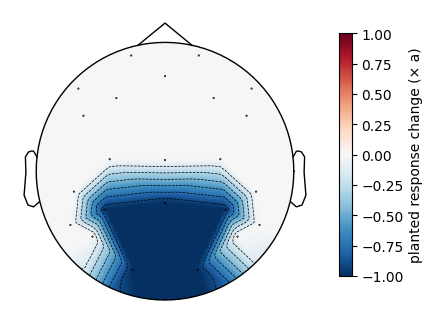

In [24]:
# THESIS FIGURE: where the attenuation plants change the response: the location-specific response is removed at the
# posterior channels (settings.POSTERIOR_CHANNELS, decoding/run_lda_injection.py, in settings.PLANT_ATTENUATION_WINDOW),
# -1 per unit of the attenuation a there, 0 elsewhere, in the style of the other topomaps
plant = np.array([-1.0 if name in settings.POSTERIOR_CHANNELS else 0.0 for name in CH_NAMES])
fig, ax = plt.subplots(figsize=(5, 4.5))
im, _ = mne.viz.plot_topomap(plant, topo_info, axes=ax, show=False, vlim=(-1, 1), cmap="RdBu_r",
                             image_interp="linear")  # cubic overshoots above 0 next to the step from -1 to 0
fig.colorbar(im, ax=ax, shrink=0.7, label="planted response change (× a)")
plt.show()
plotting.save_button(fig, save_dir=settings.THESIS_FIGURE_DIR, default_name="lda_injection_posterior_channels")


### LaBraM occlusion injection
The masked LaBraM decoder's fold models run once more on their own baseline test trials, with `a` x the subject's
location-specific response of the planted condition (class mean minus the mean over the 8 locations) removed at the posterior channels (0-0.5 s)
(`run_inference.py --class_occlusion_injection`, saved as the post-patching session of `{model}_inj_{a}`). Same model,
same trials: only the planted trials differ, so the maps compare the planted class's trials as recorded ("baseline")
with the same trials injected ("post-patching"). If the occlusion maps localise evidence, the occlusion effect drops at
the posterior clusters and stays at the frontal ones; the relative maps separate this from the overall drop of p_true.

Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading in

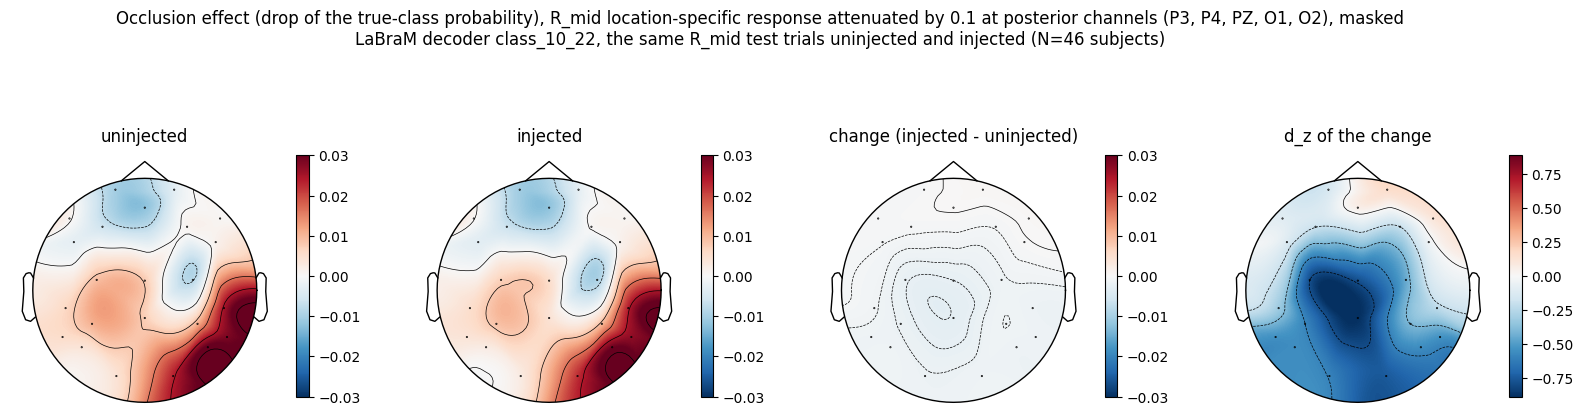

Occlusion effect (drop of the true-class probability), R_mid location-specific response attenuated by 0.1 at posterior channels (P3, P4, PZ, O1, O2), change (injected - uninjected):
  max: FP2 +0.0003, T2 +0.0002, FZ +0.0001
  min: PZ -0.0029, CZ -0.0024, C3 -0.0023


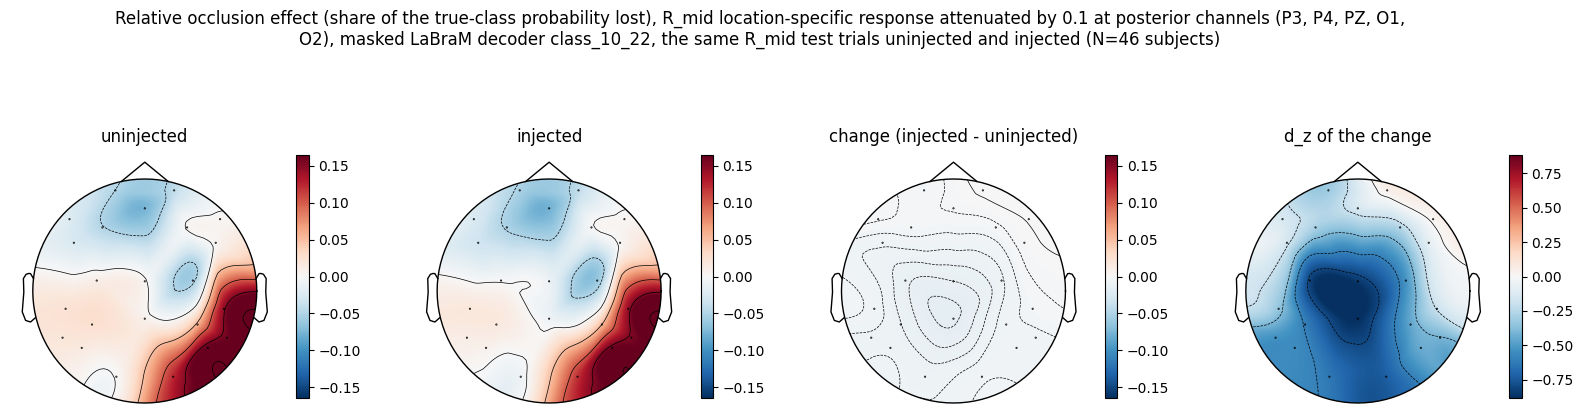

Relative occlusion effect (share of the true-class probability lost), R_mid location-specific response attenuated by 0.1 at posterior channels (P3, P4, PZ, O1, O2), change (injected - uninjected):
  max: FP2 +0.0006, T2 +0.0002, F8 -0.0012
  min: PZ -0.0155, CZ -0.0125, C3 -0.0119
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
R_mid, attenuation 0.25: p_true uninjected 0.1733 -> injec

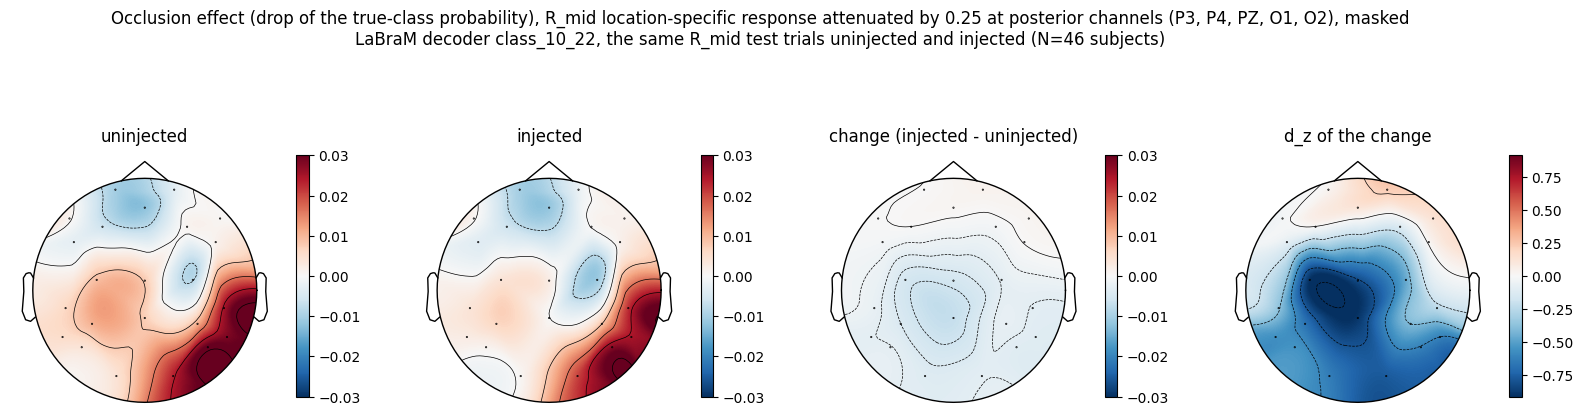

Occlusion effect (drop of the true-class probability), R_mid location-specific response attenuated by 0.25 at posterior channels (P3, P4, PZ, O1, O2), change (injected - uninjected):
  max: FP2 +0.0010, T2 +0.0007, FZ +0.0005
  min: PZ -0.0070, CZ -0.0054, C3 -0.0052


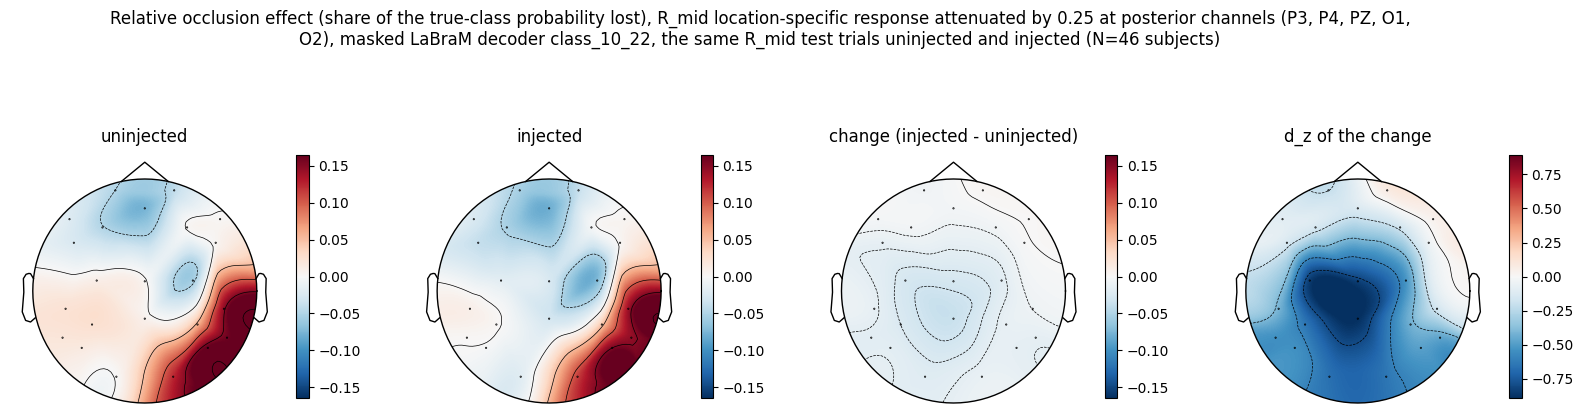

Relative occlusion effect (share of the true-class probability lost), R_mid location-specific response attenuated by 0.25 at posterior channels (P3, P4, PZ, O1, O2), change (injected - uninjected):
  max: FP2 +0.0025, T2 +0.0010, F8 -0.0015
  min: PZ -0.0365, CZ -0.0283, C3 -0.0277
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
R_mid, attenuation 0.5: p_true uninjected 0.1733 -> injec

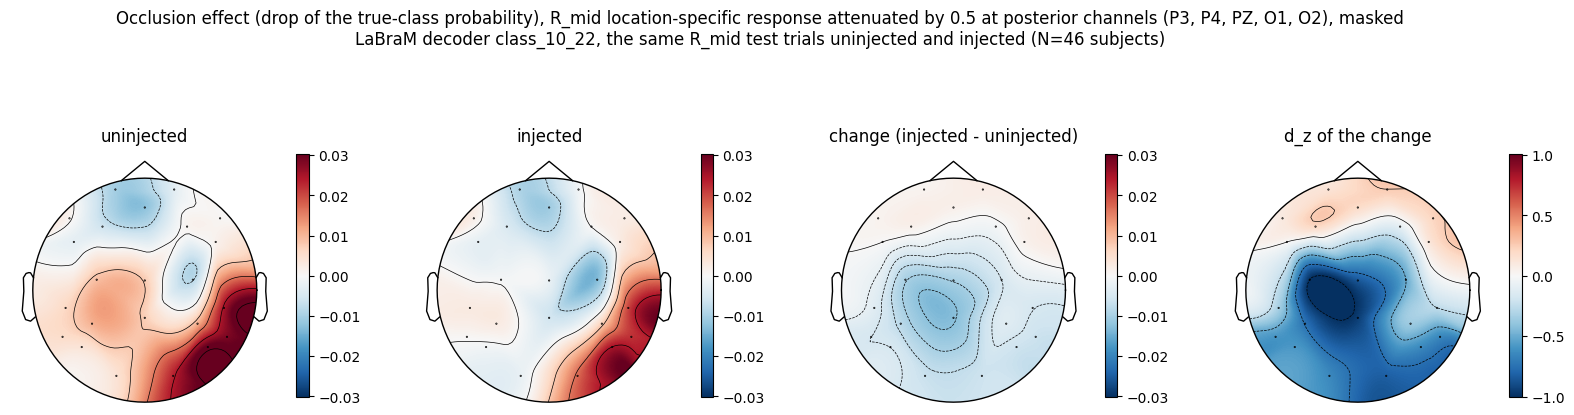

Occlusion effect (drop of the true-class probability), R_mid location-specific response attenuated by 0.5 at posterior channels (P3, P4, PZ, O1, O2), change (injected - uninjected):
  max: FP2 +0.0021, T2 +0.0018, FZ +0.0015
  min: PZ -0.0128, CZ -0.0098, C3 -0.0097


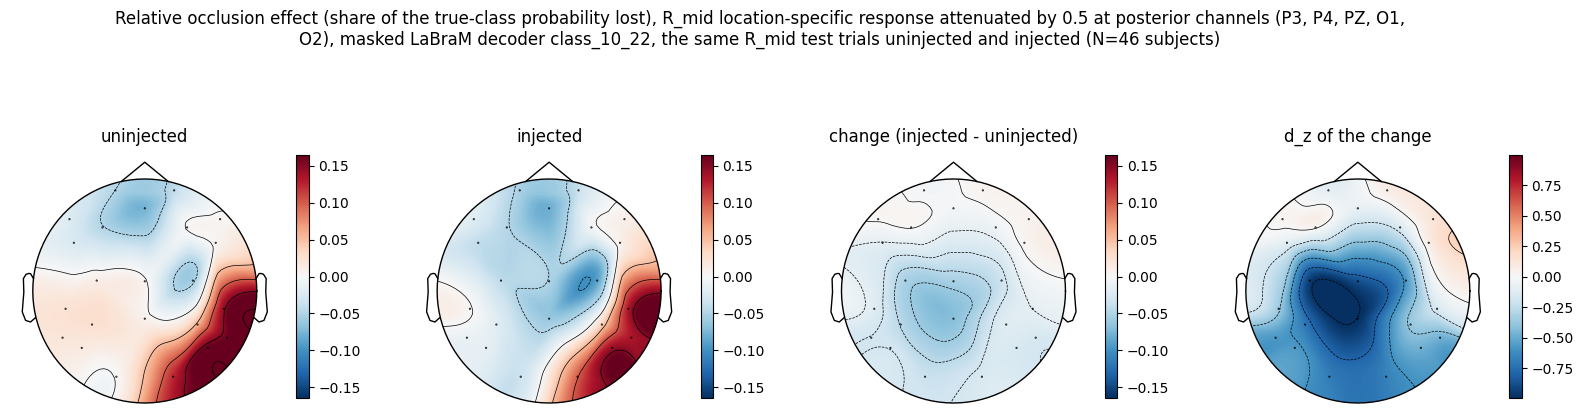

Relative occlusion effect (share of the true-class probability lost), R_mid location-specific response attenuated by 0.5 at posterior channels (P3, P4, PZ, O1, O2), change (injected - uninjected):
  max: T2 +0.0061, FP2 +0.0042, F8 +0.0033
  min: PZ -0.0690, CZ -0.0536, C3 -0.0533


In [25]:
from scipy.stats import ttest_1samp

labram_injection_model = "class_10_22"  # masked class run trained on the baseline
labram_injection_condition = "right_2"  # --injection_conditions of the injection run
labram_attenuations = [0.1, 0.25, 0.5]  # --class_occlusion_injection values that were run

planted_class = settings.CONDITION_CLASS_IDS[labram_injection_condition]
planted_label = settings.LOCATION_CLASSES[labram_injection_condition]["label"]
regular_df = load_filtered_merged(labram_injection_model, mode="channel", sessions=("baseline",))
regular_df = regular_df[regular_df["label"] == planted_class]
for attenuation in labram_attenuations:
    injected_df = load_filtered_merged(f"{labram_injection_model}_inj_{attenuation:g}", mode="channel", sessions=("postpatch",))
    inj_df = pd.concat([regular_df, injected_df[injected_df["label"] == planted_class]], ignore_index=True)
    inj_df["p_true"] = inj_df["occlusion_effect"] + inj_df["occluded_p_true"]

    # the trial-level true-class probability (the same on every channel row of a trial): it should drop
    subject_p_true = inj_df.groupby(["session", "subject"])["p_true"].mean().unstack("session").dropna()
    drop = subject_p_true["postpatch"] - subject_p_true["baseline"]
    test = ttest_1samp(drop, 0)
    print(f"{planted_label}, attenuation {attenuation:g}: p_true uninjected {subject_p_true['baseline'].mean():.4f} -> injected "
          f"{subject_p_true['postpatch'].mean():.4f}, change {drop.mean():+.4f} (t = {test.statistic:.2f}, p = {test.pvalue:.4g}, N = {len(drop)})")

    injected = f"{planted_label} location-specific response attenuated by {attenuation:g} at posterior channels ({', '.join(settings.POSTERIOR_CHANNELS)})"
    model_label = f"masked LaBraM decoder {labram_injection_model}, the same {planted_label} test trials uninjected and injected"
    file_name = f"{labram_injection_model}_inj_{attenuation:g}_{planted_label}"
    channel_change_topomaps(inj_df, f"Occlusion effect (drop of the true-class probability), {injected}", model_label=model_label,
                            session_labels=("uninjected", "injected"), save_dir=plot_dirs["labram_same_trials"], default_name=f"{file_name}_occlusion")
    channel_change_topomaps(inj_df, f"Relative occlusion effect (share of the true-class probability lost), {injected}", relative=True,
                            model_label=model_label, session_labels=("uninjected", "injected"), save_dir=plot_dirs["labram_same_trials"],
                            default_name=f"{file_name}_relative_occlusion")


### LaBraM occlusion injection, split halves
The injection above compares every trial with its own injected version. Two sessions are different trials, so here the
planted class's test trials of every subject are split into random halves (sorted ids shuffled with `random.Random(seed)`,
the second half is B, as `labram_inj_test.py --split_seed` splits the reconstruction injection): half A as recorded
("baseline") vs half B injected ("post-patching"), and the null, half A vs half B both as recorded. Same fixed model,
no session drift: the planted maps have to stand out from the null maps of the same seed for the change to be visible
against trial-to-trial noise.


Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Split seed 0, null test (no injection): p_true change (half B - half A) +0.0005 (t = 0.03, p = 0.974, N = 46)


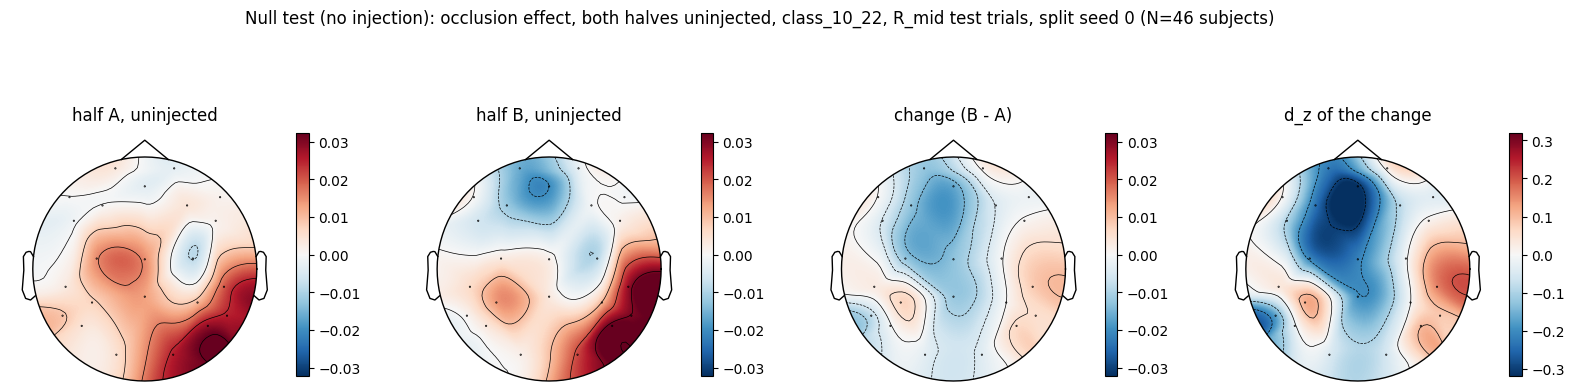

Null test (no injection): occlusion effect, both halves uninjected, change (B - A):
  max: T4 +0.0079, P3 +0.0070, T6 +0.0059
  min: FZ -0.0168, CZ -0.0131, F3 -0.0130
Split seed 0, half B injected, attenuation 0.5: p_true change (half B - half A) -0.0138 (t = -1.03, p = 0.3068, N = 46)


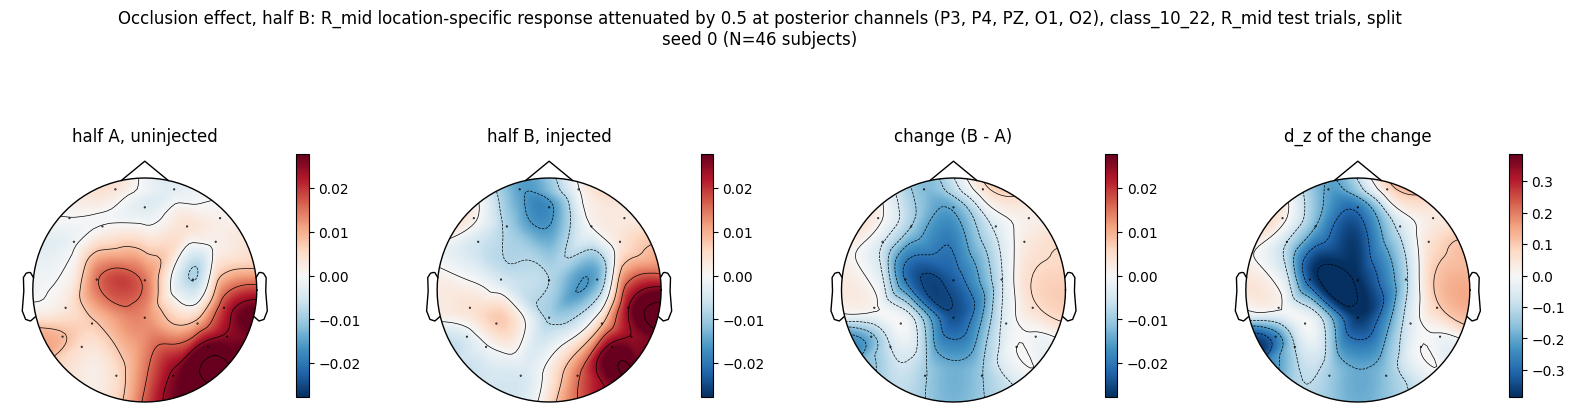

Occlusion effect, half B: R_mid location-specific response attenuated by 0.5 at posterior channels (P3, P4, PZ, O1, O2), change (B - A):
  max: T4 +0.0041, FP2 +0.0032, F8 +0.0021
  min: PZ -0.0242, CZ -0.0228, C3 -0.0204
Split seed 1, null test (no injection): p_true change (half B - half A) +0.0250 (t = 2.04, p = 0.04762, N = 46)


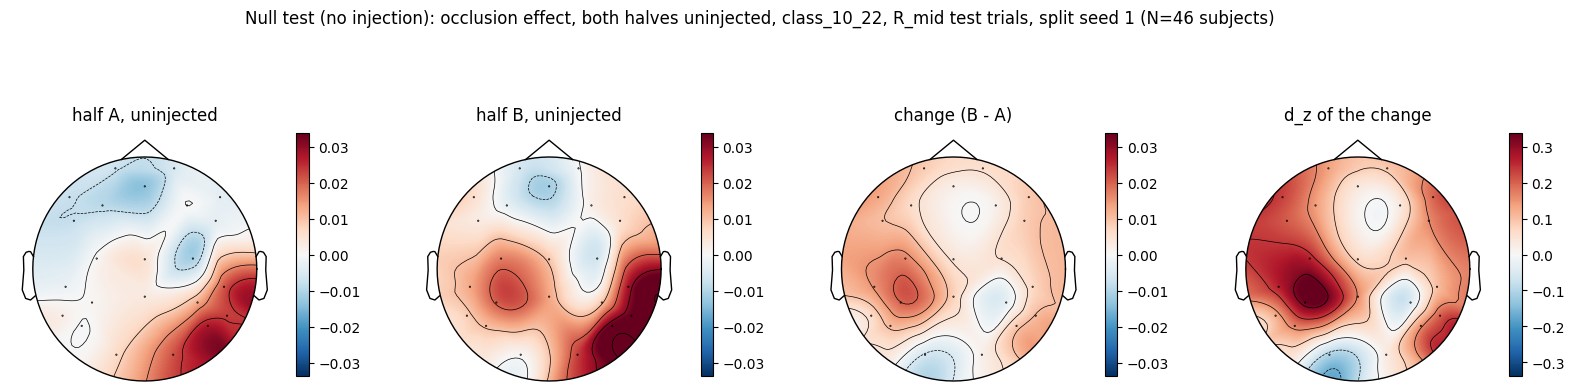

Null test (no injection): occlusion effect, both halves uninjected, change (B - A):
  max: P3 +0.0199, C3 +0.0164, T3 +0.0154
  min: O1 -0.0055, P4 -0.0032, O2 +0.0017
Split seed 1, half B injected, attenuation 0.5: p_true change (half B - half A) +0.0118 (t = 1.01, p = 0.3199, N = 46)


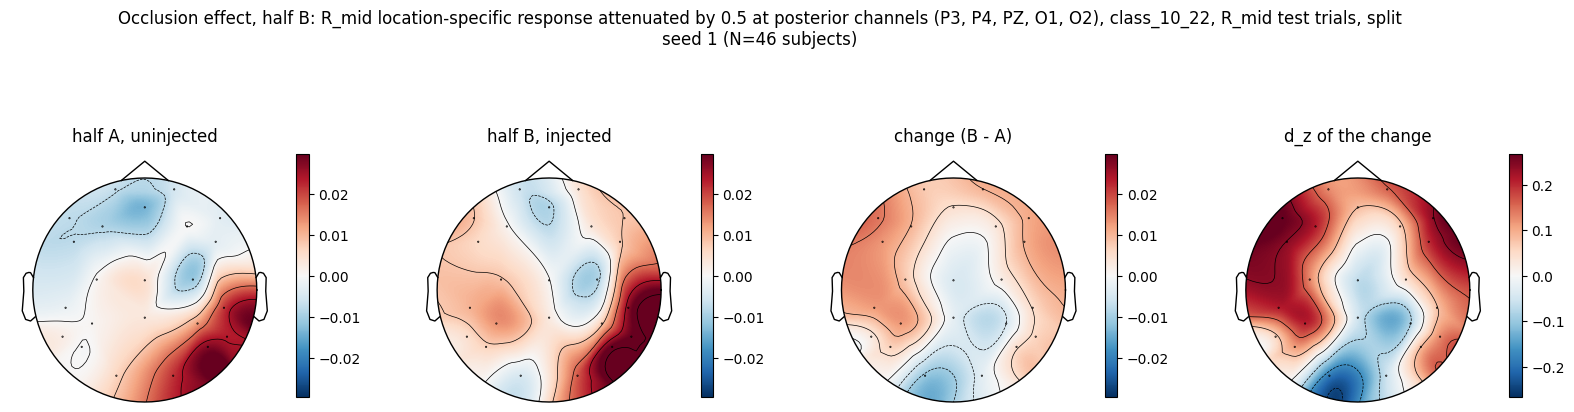

Occlusion effect, half B: R_mid location-specific response attenuated by 0.5 at posterior channels (P3, P4, PZ, O1, O2), change (B - A):
  max: T1 +0.0158, F7 +0.0129, P3 +0.0127
  min: O1 -0.0108, P4 -0.0050, CZ -0.0043
Split seed 2, null test (no injection): p_true change (half B - half A) -0.0133 (t = -1.03, p = 0.3062, N = 46)


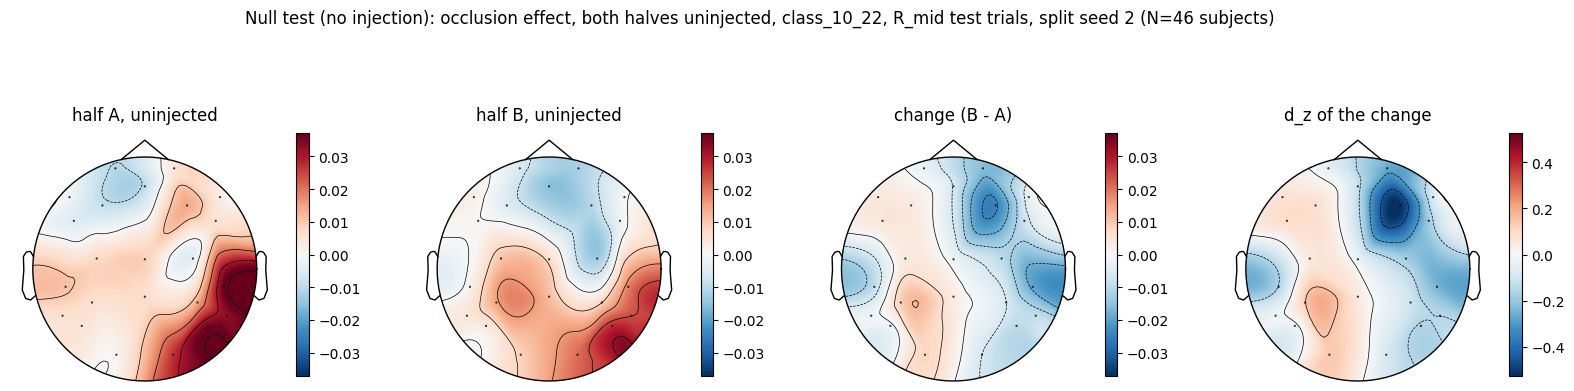

Null test (no injection): occlusion effect, both halves uninjected, change (B - A):
  max: P3 +0.0091, O1 +0.0077, F7 +0.0043
  min: F4 -0.0247, T4 -0.0190, FP2 -0.0160
Split seed 2, half B injected, attenuation 0.5: p_true change (half B - half A) -0.0274 (t = -2.12, p = 0.03953, N = 46)


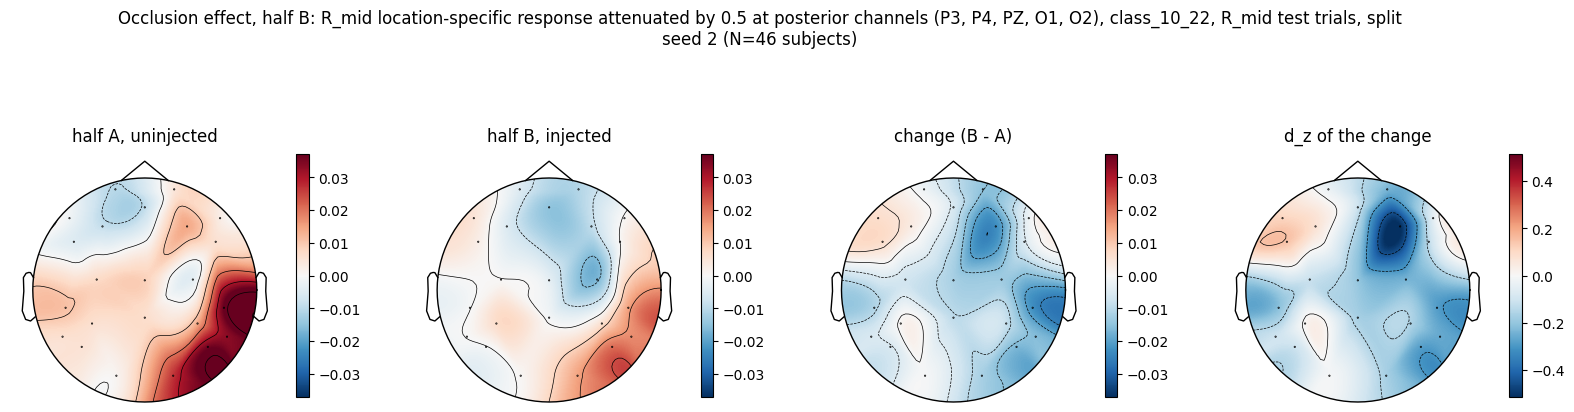

Occlusion effect, half B: R_mid location-specific response attenuated by 0.5 at posterior channels (P3, P4, PZ, O1, O2), change (B - A):
  max: T1 +0.0065, F7 +0.0064, F3 +0.0029
  min: F4 -0.0234, T4 -0.0224, T6 -0.0162
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Split seed 0, null test (no injection): p_true change (half B - half A) +0.0005 (t = 0.03, p = 0.974, N = 46)


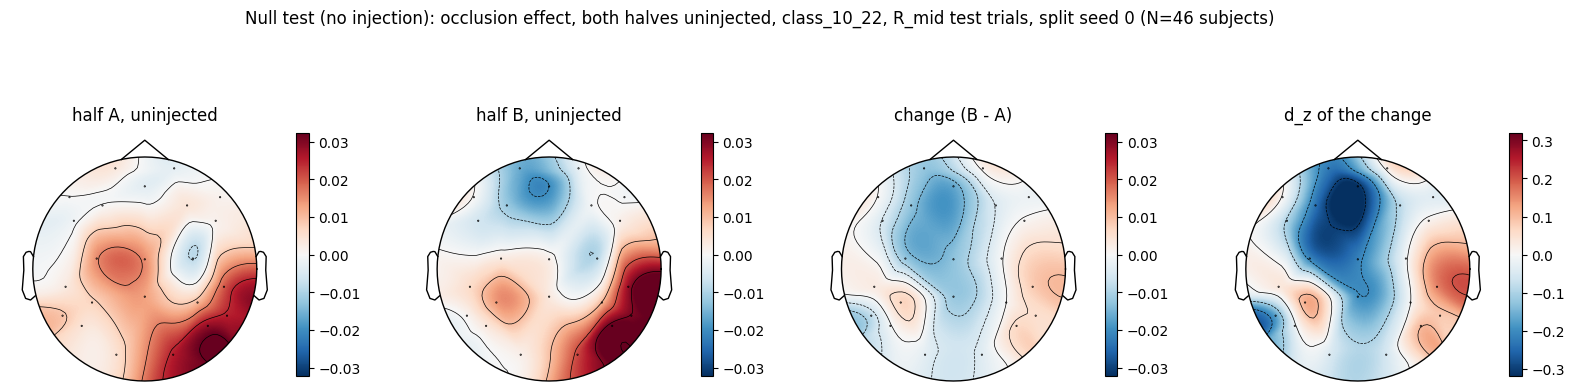

Null test (no injection): occlusion effect, both halves uninjected, change (B - A):
  max: T4 +0.0079, P3 +0.0070, T6 +0.0059
  min: FZ -0.0168, CZ -0.0131, F3 -0.0130
Split seed 0, half B injected, attenuation 1: p_true change (half B - half A) -0.0257 (t = -1.94, p = 0.05907, N = 46)


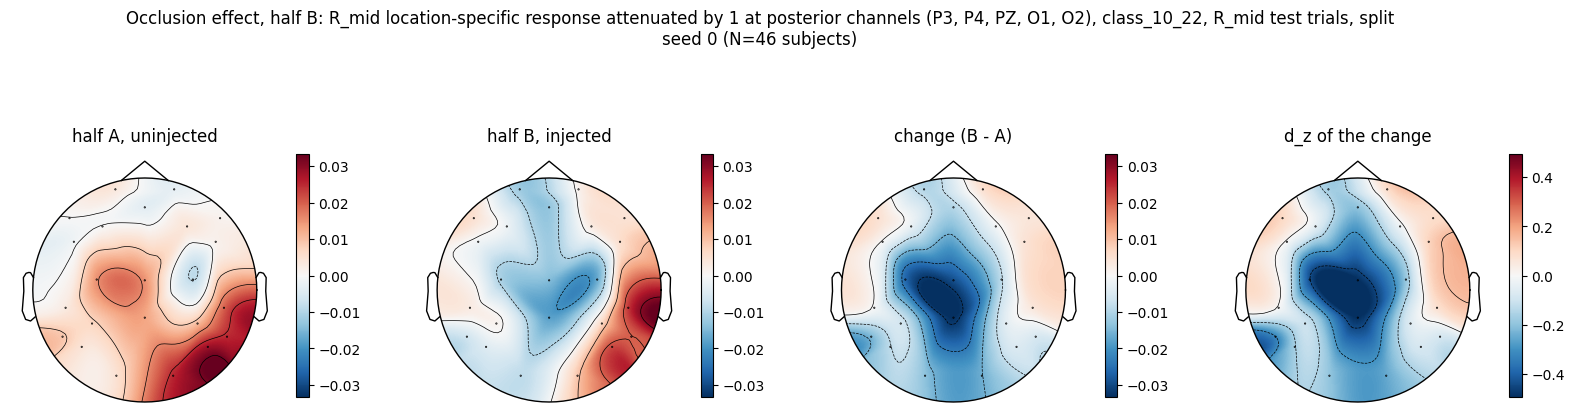

Occlusion effect, half B: R_mid location-specific response attenuated by 1 at posterior channels (P3, P4, PZ, O1, O2), change (B - A):
  max: T1 +0.0048, FP2 +0.0048, F8 +0.0043
  min: PZ -0.0333, CZ -0.0293, C3 -0.0265
Split seed 1, null test (no injection): p_true change (half B - half A) +0.0250 (t = 2.04, p = 0.04762, N = 46)


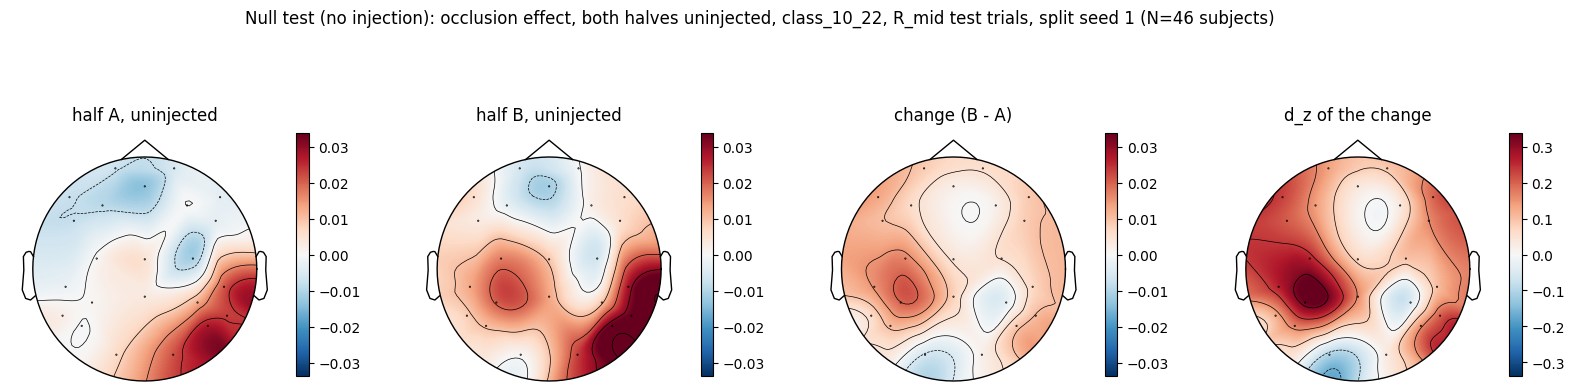

Null test (no injection): occlusion effect, both halves uninjected, change (B - A):
  max: P3 +0.0199, C3 +0.0164, T3 +0.0154
  min: O1 -0.0055, P4 -0.0032, O2 +0.0017
Split seed 1, half B injected, attenuation 1: p_true change (half B - half A) -0.0022 (t = -0.20, p = 0.8427, N = 46)


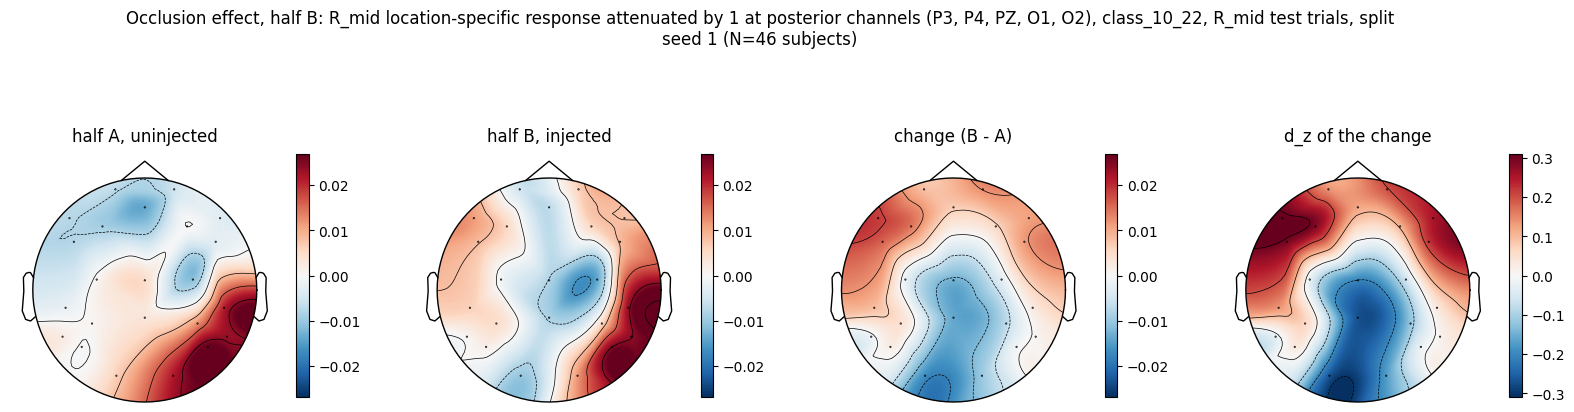

Occlusion effect, half B: R_mid location-specific response attenuated by 1 at posterior channels (P3, P4, PZ, O1, O2), change (B - A):
  max: T1 +0.0186, F7 +0.0157, F3 +0.0141
  min: O1 -0.0165, PZ -0.0138, CZ -0.0127
Split seed 2, null test (no injection): p_true change (half B - half A) -0.0133 (t = -1.03, p = 0.3062, N = 46)


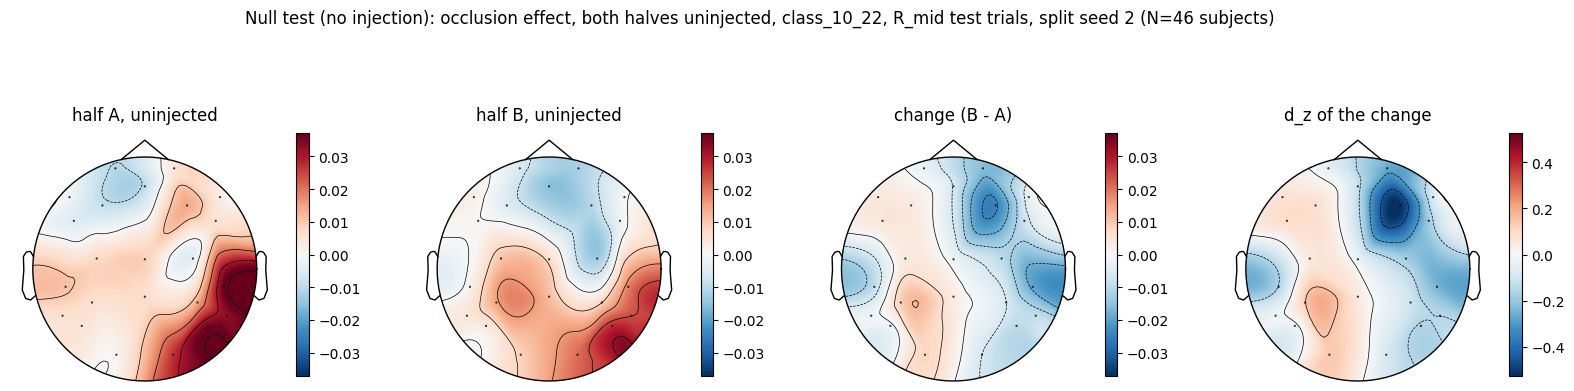

Null test (no injection): occlusion effect, both halves uninjected, change (B - A):
  max: P3 +0.0091, O1 +0.0077, F7 +0.0043
  min: F4 -0.0247, T4 -0.0190, FP2 -0.0160
Split seed 2, half B injected, attenuation 1: p_true change (half B - half A) -0.0404 (t = -3.10, p = 0.003304, N = 46)


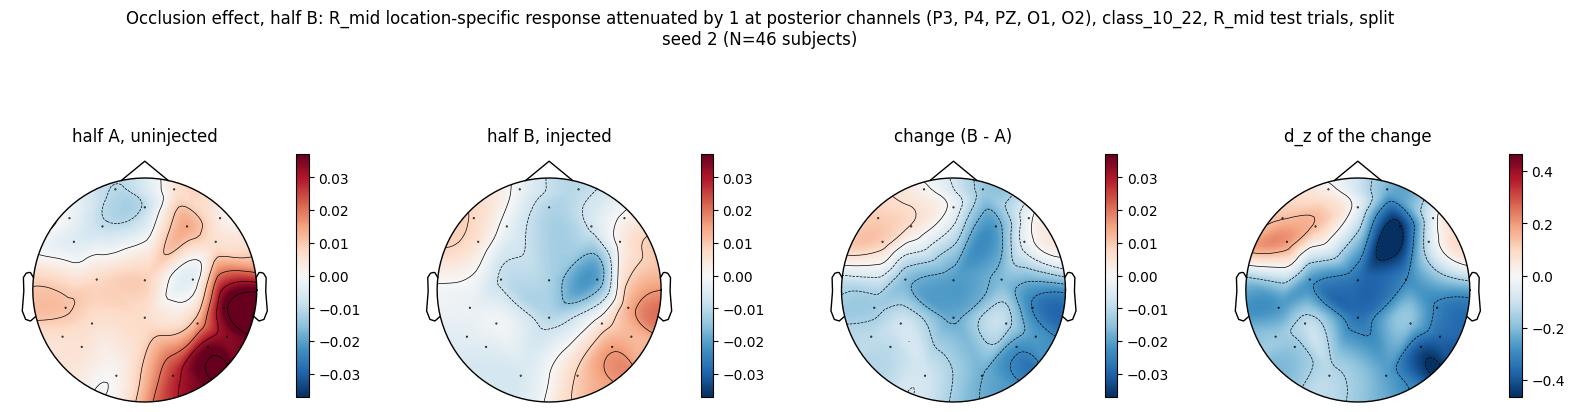

Occlusion effect, half B: R_mid location-specific response attenuated by 1 at posterior channels (P3, P4, PZ, O1, O2), change (B - A):
  max: T1 +0.0092, F7 +0.0087, F3 +0.0056
  min: T4 -0.0244, T6 -0.0216, A2 -0.0211


In [26]:
import random

labram_split_seeds = [0, 1, 2]
labram_split_attenuations = [0.5, 1]  # of labram_attenuations


def split_half_b(df, seed):
    """True for the rows of half B: every subject's trial ids of every condition sorted, shuffled with random.Random(seed), the second half."""
    rng = random.Random(seed)
    half_b = set()
    for (subject, condition), group in df[["subject", "condition", "id"]].drop_duplicates().groupby(["subject", "condition"], sort=True):
        ids = sorted(group["id"])
        rng.shuffle(ids)
        half_b |= {(subject, condition, idx) for idx in ids[len(ids) // 2:]}
    return pd.MultiIndex.from_frame(df[["subject", "condition", "id"]]).isin(list(half_b))


for attenuation in labram_split_attenuations:
    injected_df = load_filtered_merged(f"{labram_injection_model}_inj_{attenuation:g}", mode="channel", sessions=("postpatch",))
    injected_df = injected_df[injected_df["label"] == planted_class]
    for seed in labram_split_seeds:
        half_a = regular_df[~split_half_b(regular_df, seed)]
        pairs = {"null": regular_df[split_half_b(regular_df, seed)].assign(session="postpatch"),
                 "planted": injected_df[split_half_b(injected_df, seed)]}
        for pair, half_b in pairs.items():
            split_df = pd.concat([half_a, half_b], ignore_index=True)
            split_df["p_true"] = split_df["occlusion_effect"] + split_df["occluded_p_true"]
            subject_p_true = split_df.groupby(["session", "subject"])["p_true"].mean().unstack("session").dropna()
            change = subject_p_true["postpatch"] - subject_p_true["baseline"]
            test = ttest_1samp(change, 0)
            what = "null test (no injection)" if pair == "null" else f"half B injected, attenuation {attenuation:g}"
            print(f"Split seed {seed}, {what}: p_true change (half B - half A) {change.mean():+.4f} "
                  f"(t = {test.statistic:.2f}, p = {test.pvalue:.4g}, N = {len(change)})")
            # half A in the first slot, half B in the second: the change map is half B - half A
            if pair == "null":
                title, labels = "Null test (no injection): occlusion effect, both halves uninjected", ("half A, uninjected", "half B, uninjected")
            else:
                title = (f"Occlusion effect, half B: {planted_label} location-specific response attenuated by {attenuation:g} at posterior channels "
                         f"({', '.join(settings.POSTERIOR_CHANNELS)})")
                labels = ("half A, uninjected", "half B, injected")
            file_name = f"{labram_injection_model}_inj_{attenuation:g}_{planted_label}_split{seed}_{'null' if pair == 'null' else 'injected'}"
            channel_change_topomaps(split_df, title, session_labels=labels, change_label="change (B - A)",
                                    model_label=f"{labram_injection_model}, {planted_label} test trials, split seed {seed}",
                                    save_dir=plot_dirs["labram_split"], default_name=f"{file_name}_occlusion")


Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading in

,test,a,drop,se,n
0,same trials,0.10,0.003253,0.000483,46
1,split,0.10,-0.001194,0.012867,46
2,same trials,0.25,0.007716,0.001041,46
3,split,0.25,0.002997,0.012772,46
4,same trials,0.50,0.014651,0.001811,46
5,split,0.50,0.009669,0.012660,46
6,same trials,1.00,0.027749,0.003265,46
7,split,1.00,0.022615,0.012507,46


LaBraM true-class probability drop, same trials: slope of the mean drop on a = 0.0271 (n = 4 attenuations)
LaBraM true-class probability drop, split: null band -0.0295 to +0.0212
LaBraM true-class probability drop, split: slope of the mean drop on a = 0.0264 (n = 4 attenuations)


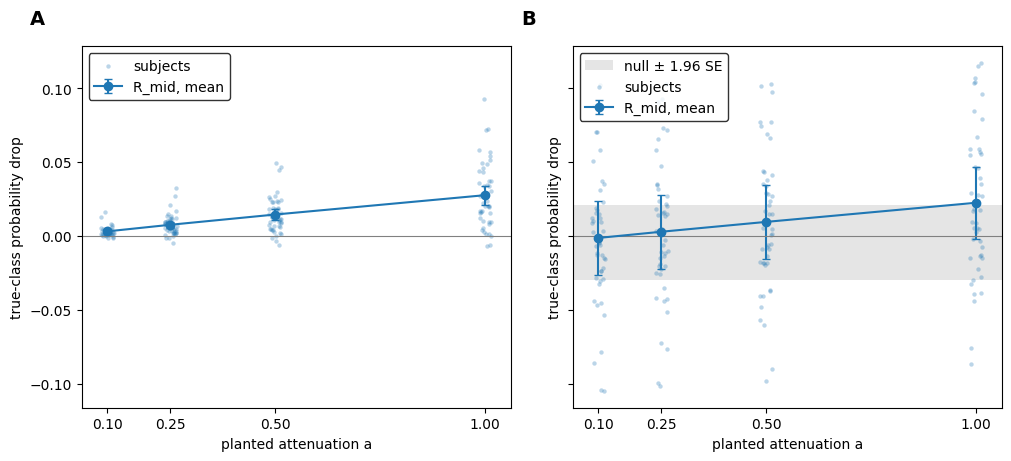

In [27]:
# THESIS FIGURE: drop of the masked LaBraM decoder's true-class probability of the planted class (the planted
# direction is positive) vs the attenuation a, in the style of the LDA recovery figure. Dots: the subjects, line: their
# mean ± 1.96 SE.
# A: the same trials, uninjected - injected. B: two different sets of trials, as two sessions: half A uninjected - half B
# injected, the subject x split values of the splits recovery_split_seeds pooled (pooled_mean_se: mean over all values,
# single-split SE), dots: every subject's mean over the splits. Every a uses the same halves, so their difference shifts
# all points alike. Grey band in B: the null of the splits (half A - half B, both uninjected, pooled the same way), mean
# ± 1.96 SE.
recovery_attenuations = [0.1, 0.25, 0.5, 1]  # a of the {labram_injection_model}_inj_{a} runs shown
recovery_split_seeds = labram_split_seeds  # the splits averaged in panel B (and in the split AUC drop below)


def subject_p_true(trials):
    """Every subject's mean true-class probability of the planted class's trials."""
    return trials.groupby("subject")[f"p{planted_class}"].mean()


def pooled_mean_se(per_seed):
    """
    Mean and single-split SE of per-subject Series of several split seeds (one per seed), every subject x seed value
    pooled: the mean over all values, SE = pooled SD (every value centred on its seed's mean) / sqrt(number of subjects),
    the SE of one split. Averaging every subject over the seeds first would shrink the SE below a single split's.
    """
    values = pd.concat(dict(enumerate(per_seed)), names=["seed", "subject"]).dropna()
    centred = values - values.groupby(level="seed").transform("mean")
    n_seeds, n_subjects = values.index.get_level_values("seed").nunique(), values.index.get_level_values("subject").nunique()
    return {"drop": values.mean(), "se": np.sqrt((centred ** 2).sum() / (len(values) - n_seeds)) / np.sqrt(n_subjects), "n": n_subjects}


def mean_se(drop):
    drop = drop.dropna()
    return {"drop": drop.mean(), "se": drop.sem(), "n": len(drop)}


regular_trials = load_filtered_merged(labram_injection_model, sessions=("baseline",))
regular_trials = regular_trials[regular_trials["label"] == planted_class]
half_b = {seed: split_half_b(regular_trials, seed) for seed in recovery_split_seeds}
half_a = {seed: subject_p_true(regular_trials[~half_b[seed]]) for seed in recovery_split_seeds}
null = pooled_mean_se([half_a[seed] - subject_p_true(regular_trials[half_b[seed]]) for seed in recovery_split_seeds])
rows, subject_drops = [], []
for attenuation in recovery_attenuations:
    injected_trials = load_filtered_merged(f"{labram_injection_model}_inj_{attenuation:g}", sessions=("postpatch",))
    injected_trials = injected_trials[injected_trials["label"] == planted_class]
    same = subject_p_true(regular_trials) - subject_p_true(injected_trials)
    split_per_seed = [half_a[seed] - subject_p_true(injected_trials[split_half_b(injected_trials, seed)]) for seed in recovery_split_seeds]
    split = pd.concat(split_per_seed, axis=1).mean(axis=1)  # every subject's mean over the splits, for the dots
    rows += [{"test": "same trials", "a": attenuation, **mean_se(same)}, {"test": "split", "a": attenuation, **pooled_mean_se(split_per_seed)}]
    subject_drops += [pd.DataFrame({"test": test, "a": attenuation, "drop": drop.dropna()}) for test, drop in (("same trials", same), ("split", split))]
labram_recovery = pd.DataFrame(rows)
subject_drops = pd.concat(subject_drops)
print(f"null (split seeds {recovery_split_seeds} pooled): {null['drop']:+.4f} (SE {null['se']:.4f}, N = {null['n']})")
display(labram_recovery)

fig, axd = plt.subplot_mosaic([["A", "B"]], figsize=(10, 4.5), layout="constrained", sharey=True)
for key, test in (("A", "same trials"), ("B", "split")):
    ax = axd[key]
    if test == "split":
        low, high = null["drop"] + np.array([-1.96, 1.96]) * null["se"]  # mean ± 1.96 SE over subjects
        ax.axhspan(low, high, color="gray", alpha=0.2, linewidth=0, label="null ± 1.96 SE")
        print(f"LaBraM true-class probability drop, split: null band {low:+.4f} to {high:+.4f}")
    dots = subject_drops[subject_drops["test"] == test]
    jitter = np.random.default_rng(0).uniform(-0.015, 0.015, len(dots))  # spreads the subjects of one a sideways
    ax.scatter(dots["a"] + jitter, dots["drop"], s=10, color="C0", alpha=0.3, linewidths=0, label="subjects")
    rows = labram_recovery[labram_recovery["test"] == test]
    ax.errorbar(rows["a"], rows["drop"], yerr=1.96 * rows["se"], marker="o", capsize=3, color="C0", label=f"{planted_label}, mean")
    print(f"LaBraM true-class probability drop, {test}: slope of the mean drop on a = {np.polyfit(rows['a'], rows['drop'], 1)[0]:.4f} (n = {len(rows)} attenuations)")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_xticks(recovery_attenuations)
    ax.set_xlabel("planted attenuation a")
    ax.set_ylabel("true-class probability drop")
    ax.legend(loc="upper left").get_frame().set_edgecolor("black")
for key, ax in axd.items():
    ax.text(-0.12, 1.05, key, transform=ax.transAxes, fontsize=14, fontweight="bold", va="bottom", gid="panel_label")
plt.show()
plotting.save_panels(fig, axd, settings.THESIS_FIGURE_DIR, settings.SUBFIGURES_DIR, default_name="labram_injection_recovery")


Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading in

,class,a,drop,se,n
0,R_mid,0.10,0.004790,0.000424,46
1,R_mid,0.25,0.011643,0.001033,46
2,R_mid,0.50,0.023948,0.002127,46
3,R_mid,1.00,0.048026,0.004627,46


split seeds [0, 1, 2] pooled, half A uninjected - half B injected; null (both uninjected): R_mid +0.0024 (SE 0.0234), L_mid -0.0067 (SE 0.0226)


,class,a,drop,se,n
0,R_mid,0.10,0.006918,0.023308,46
1,R_mid,0.25,0.013692,0.023251,46
2,R_mid,0.50,0.025360,0.023171,46
3,R_mid,1.00,0.048959,0.023298,46


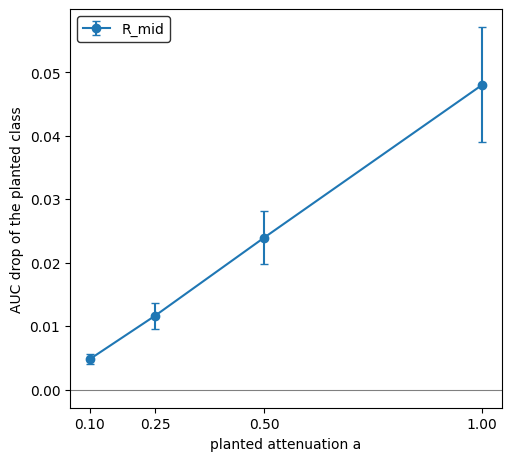

In [28]:
# THESIS FIGURE: the planted class's AUC drop of the masked LaBraM decoder vs the attenuation a, on the same trials, as
# panel B of the LDA recovery figure. Per subject the one-vs-rest AUC of the planted class over all the subject's test
# trials (core.decoding.metrics.ovr_auc on the class probabilities), uninjected - injected; mean ± 1.96 SE over subjects.
# Also, with trial-to-trial noise (labram_auc_split, panel B of the recovery figure below): the AUC over half A's trials
# uninjected - the AUC over half B's trials injected (split_half_b, every class's trials halved), the subject x split
# values of the splits recovery_split_seeds pooled (pooled_mean_se), not null-subtracted, and its null (labram_auc_null):
# half A - half B, both uninjected, pooled the same way.
# Runs: run_inference.py --class_occlusion_injection ... --injection_conditions <condition>; a missing run is skipped
from core.decoding import metrics as decoding_metrics

auc_injection_runs = {"right_2": f"{labram_injection_model}_inj_{{a:g}}",  # {a}: the attenuation
                      "left_2": f"{labram_injection_model}_inj_left_2_{{a:g}}"}


def subject_class_auc(trials, class_id):
    """Every subject's one-vs-rest AUC of class_id over all the subject's trials (class_trials_frame)."""
    proba = [f"p{k}" for k in range(settings.N_LOCATION_CLASSES)]
    return pd.Series({subject: decoding_metrics.ovr_auc(rows["label"].to_numpy(), rows[proba].to_numpy(), settings.N_LOCATION_CLASSES)[class_id]
                      for subject, rows in trials.groupby("subject")})


uninjected_trials = load_filtered_merged(labram_injection_model, sessions=("baseline",))
uninjected_half_b = {seed: split_half_b(uninjected_trials, seed) for seed in recovery_split_seeds}
rows, split_rows, labram_auc_null = [], [], {}
for condition, run_name in auc_injection_runs.items():
    class_id, label = settings.CONDITION_CLASS_IDS[condition], settings.LOCATION_CLASSES[condition]["label"]
    uninjected_auc = subject_class_auc(uninjected_trials, class_id)
    half_a_auc = {seed: subject_class_auc(uninjected_trials[~half], class_id) for seed, half in uninjected_half_b.items()}
    labram_auc_null[label] = pooled_mean_se([half_a_auc[seed] - subject_class_auc(uninjected_trials[half], class_id)
                                             for seed, half in uninjected_half_b.items()])
    for attenuation in recovery_attenuations:
        run = run_name.format(a=attenuation)
        if not (settings.INFERENCE_DIR / run).exists():
            print(f"{label}, a = {attenuation:g}: no run {run}, skipped")
            continue
        injected_trials = load_filtered_merged(run, sessions=("postpatch",))
        drop = (uninjected_auc - subject_class_auc(injected_trials, class_id)).dropna()
        rows.append({"class": label, "a": attenuation, "drop": drop.mean(), "se": drop.sem(), "n": len(drop)})
        split_rows.append({"class": label, "a": attenuation,
                           **pooled_mean_se([half_a_auc[seed] - subject_class_auc(injected_trials[split_half_b(injected_trials, seed)], class_id)
                                             for seed in recovery_split_seeds])})
labram_auc_drop, labram_auc_split = pd.DataFrame(rows), pd.DataFrame(split_rows)
display(labram_auc_drop)
print(f"split seeds {recovery_split_seeds} pooled, half A uninjected - half B injected; null (both uninjected): "
      + ", ".join(f"{label} {null['drop']:+.4f} (SE {null['se']:.4f})" for label, null in labram_auc_null.items()))
display(labram_auc_split)

fig, ax = plt.subplots(figsize=(5, 4.5), layout="constrained")
for label, rows in labram_auc_drop.groupby("class"):
    ax.errorbar(rows["a"], rows["drop"], yerr=1.96 * rows["se"], marker="o", capsize=3, label=label)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xticks(recovery_attenuations)
ax.set_xlabel("planted attenuation a")
ax.set_ylabel("AUC drop of the planted class")
ax.legend(loc="upper left").get_frame().set_edgecolor("black")
plt.show()
plotting.save_button(fig, save_dir=settings.THESIS_FIGURE_DIR, default_name="labram_injection_auc_drop")


LDA patched - other accuracy, mid: null band -0.03458 to +0.03458 (seeds [0, 1, 2], 45 subjects)
LDA attenuation, L_mid: slope of the recovered AUC drop on a = 0.0007 (n = 4 attenuations)
LDA attenuation, R_mid: slope of the recovered AUC drop on a = -0.0037 (n = 4 attenuations)
LaBraM AUC drop, R_mid: null band -0.0434 to +0.0483
LaBraM attenuation, R_mid: slope of the AUC drop on a = 0.0468 (n = 4 attenuations)
LDA patched - other latency, near: null band -14.98 to +14.98 (seeds [0, 1, 2], 45 subjects)
LDA delay, L_near: slope of the recovered on the planted delay = 1.446 (1 = fully recovered, n = 3 delays)
LDA delay, R_near: slope of the recovered on the planted delay = 1.120 (1 = fully recovered, n = 3 delays)


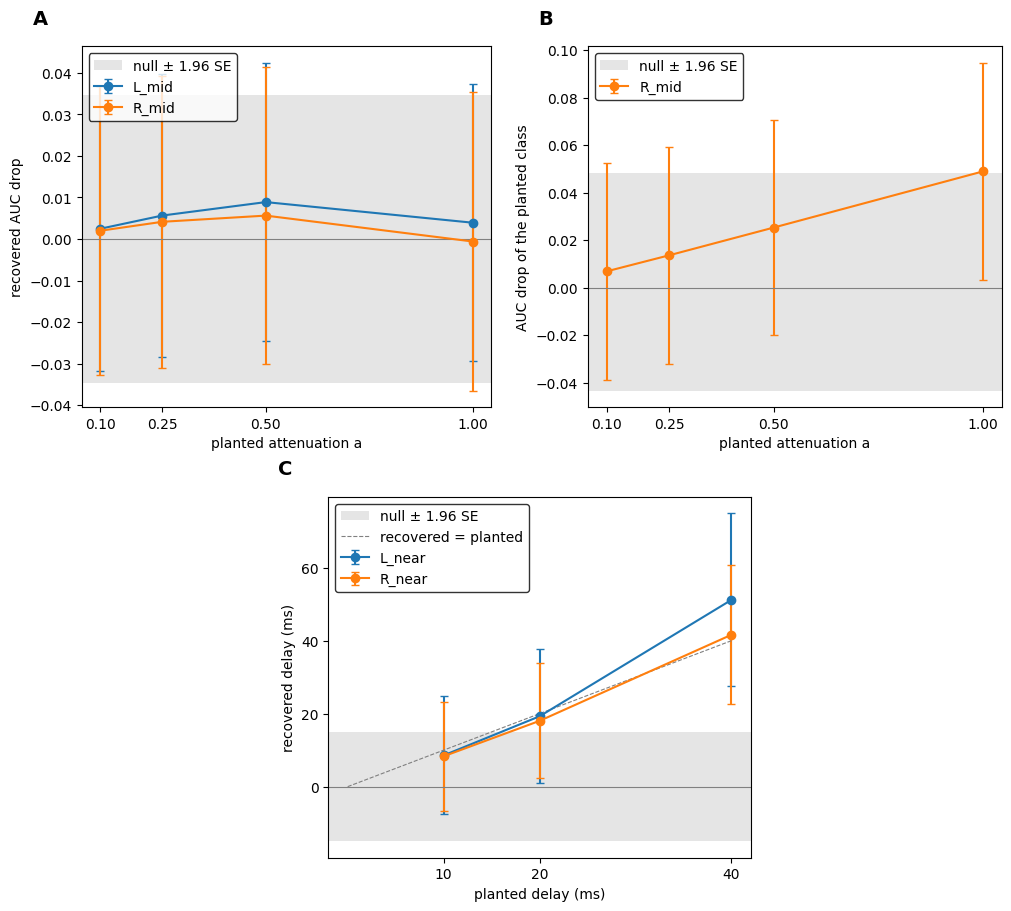

In [29]:
# THESIS FIGURE: recovery of the planted changes. A: the sliding LDA, location-specific (class) attenuation, by the
# Task B side contrast (patched - other accuracy) at the planted class's eccentricity (mid). B: the masked LaBraM
# decoder, the planted class's AUC drop with trial-to-trial noise (labram_auc_split, cell above: the AUC over half A's
# trials uninjected - over half B's trials injected, the subject x split values of recovery_split_seeds pooled). C: the
# sliding LDA, delays,
# by the patched - other latency at near.
# LDA: per-subject values of all split seeds (the _subjects.csv files of the run_lda cell; latency: the subjects' jackknife
# pseudo-values), every subject x seed row pooled. Recovered = planted run - null run of the same split and subject
# (removes the split's own offset between the halves), signed so that the planted direction is positive; points: the mean
# over all rows (latency: the mean over the seeds of the latency of the mean curves, as in the Task B tables, not the
# pseudo-values' bias-corrected mean). Error bars: ±1.96 SE of the planted run (the planted and null runs share trials, so the SE of the
# difference is smaller). Grey band: ±1.96 SE of the null run around 0, the 95 % range of the split's own noise in a
# group estimate, which the recovered values have to exceed. SE = pooled SD / sqrt(number of subjects), the pooled SD from
# all seeds' rows, each centred on its seed's mean (the latency pseudo-values' means shift between the seeds): the SE of a
# single split (SD / sqrt(rows) would shrink it as if every seed added new subjects). B: ±1.96 SE, the same single-split
# SE of its pooled subject x split values. B is not null-subtracted (with the same half A, planted - null would cancel
# the trial-to-trial noise); its grey band is the null itself (half A - half B, both uninjected), mean ± 1.96 SE the
# same way

null_subjects = pd.read_csv(stats_dir / "LDA" / f"{injection_prefix}_null_subjects.csv")
planted_subjects = pd.read_csv(stats_dir / "LDA" / f"{injection_prefix}_recovery_subjects.csv")
planted_subjects = planted_subjects.merge(null_subjects, on=["seed", "subject", "measure", "ecc"], suffixes=("", "_null"))
planted_subjects["recovered"] = (planted_subjects["estimate"] - planted_subjects["estimate_null"]) * planted_subjects["sign"]


def single_split_se(rows, column):
    """
    SE of a single split from per-subject rows of several split seeds: the pooled SD (every row centred on its seed's mean,
    n_rows - n_seeds degrees of freedom) / sqrt(number of subjects).
    """
    rows = rows.dropna(subset=[column])
    centred = rows[column] - rows.groupby("seed")[column].transform("mean")
    pooled_sd = np.sqrt((centred ** 2).sum() / (len(rows) - rows["seed"].nunique()))
    return pooled_sd / np.sqrt(rows["subject"].nunique())


side = (planted_subjects.groupby(["type", "class", "size", "measure", "ecc"])
        .apply(lambda rows: pd.Series({"recovered": rows["recovered"].mean(), "se": single_split_se(rows, "value"),
                                       "n": rows["subject"].nunique(), "seeds": rows["seed"].nunique()}))
        .reset_index())


def null_band(ax, rows, scale=1.0):
    """Grey band of ±1.96 single-split SE of the null run (of the rows' measure and eccentricity, seeds pooled) around 0."""
    (measure, ecc), = rows[["measure", "ecc"]].drop_duplicates().itertuples(index=False)
    null_rows = null_subjects[(null_subjects["measure"] == measure) & (null_subjects["ecc"] == ecc)]
    se = single_split_se(null_rows, "value") * scale
    ax.axhspan(-1.96 * se, 1.96 * se, color="gray", alpha=0.2, linewidth=0, label="null ± 1.96 SE")
    print(f"LDA patched - other {measure}, {ecc}: null band {-1.96 * se:+.4g} to {1.96 * se:+.4g} "
          f"(seeds {sorted(null_rows['seed'].unique())}, {null_rows['subject'].nunique()} subjects)")


attenuation = side[side["type"] == "classattenuation"]
delay = side[(side["type"] == "delay") & (side["ecc"] == "near")]
colors = {label: f"C{i}" for i, label in enumerate(sorted(attenuation["class"].unique()))}  # a class has one colour in A and B

fig, axd = plt.subplot_mosaic([["A", "A", "B", "B"], [".", "C", "C", "."]], figsize=(10, 9), layout="constrained")

ax = axd["A"]
null_band(ax, attenuation)
for label, rows in attenuation.groupby("class"):
    ax.errorbar(rows["size"], rows["recovered"], yerr=1.96 * rows["se"], marker="o", capsize=3, color=colors[label], label=label)
    print(f"LDA attenuation, {label}: slope of the recovered AUC drop on a = {np.polyfit(rows['size'], rows['recovered'], 1)[0]:.4f} (n = {len(rows)} attenuations)")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xticks(np.sort(attenuation["size"].unique()))
ax.set_xlabel("planted attenuation a")
ax.set_ylabel("recovered AUC drop")
ax.legend(loc="upper left").get_frame().set_edgecolor("black")

ax = axd["B"]
for i, (label, rows) in enumerate(labram_auc_split.groupby("class")):
    null_auc = labram_auc_null[label]
    low, high = null_auc["drop"] + np.array([-1.96, 1.96]) * null_auc["se"]  # mean ± 1.96 SE over subjects
    ax.axhspan(low, high, color="gray", alpha=0.2, linewidth=0, label="null ± 1.96 SE" if i == 0 else None)
    print(f"LaBraM AUC drop, {label}: null band {low:+.4f} to {high:+.4f}")
    ax.errorbar(rows["a"], rows["drop"], yerr=1.96 * rows["se"], marker="o", capsize=3, color=colors.get(label), label=label)
    print(f"LaBraM attenuation, {label}: slope of the AUC drop on a = {np.polyfit(rows['a'], rows['drop'], 1)[0]:.4f} (n = {len(rows)} attenuations)")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xticks(recovery_attenuations)
ax.set_xlabel("planted attenuation a")
ax.set_ylabel("AUC drop of the planted class")
ax.legend(loc="upper left").get_frame().set_edgecolor("black")

ax = axd["C"]
null_band(ax, delay, scale=1000)
for label, rows in delay.groupby("class"):
    ax.errorbar(rows["size"] * 1000, rows["recovered"] * 1000, yerr=1.96 * rows["se"] * 1000, marker="o", capsize=3, label=label)
    print(f"LDA delay, {label}: slope of the recovered on the planted delay = {np.polyfit(rows['size'], rows['recovered'], 1)[0]:.3f} (1 = fully recovered, n = {len(rows)} delays)")
sizes = np.sort(delay["size"].unique()) * 1000
ax.plot([0, sizes.max()], [0, sizes.max()], color="gray", linestyle="--", linewidth=0.8, label="recovered = planted")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xticks(sizes)
ax.set_xlabel("planted delay (ms)")
ax.set_ylabel("recovered delay (ms)")
ax.legend(loc="upper left").get_frame().set_edgecolor("black")

for key, ax in axd.items():
    ax.text(-0.12, 1.05, key, transform=ax.transAxes, fontsize=14, fontweight="bold", va="bottom", gid="panel_label")
plt.show()
plotting.save_panels(fig, axd, settings.THESIS_FIGURE_DIR, settings.SUBFIGURES_DIR, default_name="lda_injection_recovery")


### LaBraM occlusion injection, within session
The check of the within-session comparison: two models trained on different trials, compared through their occlusion
maps. Every subject's baseline trials are split into two pseudo-sessions (`run_general_finetune.py --pseudo_session`):
one model trained on pseudo pre, one on pseudo post with the location-specific posterior response of the planted
condition removed (`plant_class_attenuation`), and one on pseudo post without a plant (null). Each model's occlusion is
run on its own test trials (`run_inference.py`). The maps compare the planted class's trials, in the terms of the
split-half cell: half A (pseudo pre) with model A, its model, vs half B (pseudo post) with model B; change = B - A.
- **Planted pair**: the occlusion effect drops at the posterior clusters.
- **Null pair**: no such pattern; its differences are those of two models trained on different trials, the floor the
  real within-session difference has to exceed.


Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
half B injected, attenuation 1: p_true half A 0.1675 -> half B 0.1588, change (B - A) -0.0087 (t = -0.50, p = 0.6218, N = 46)


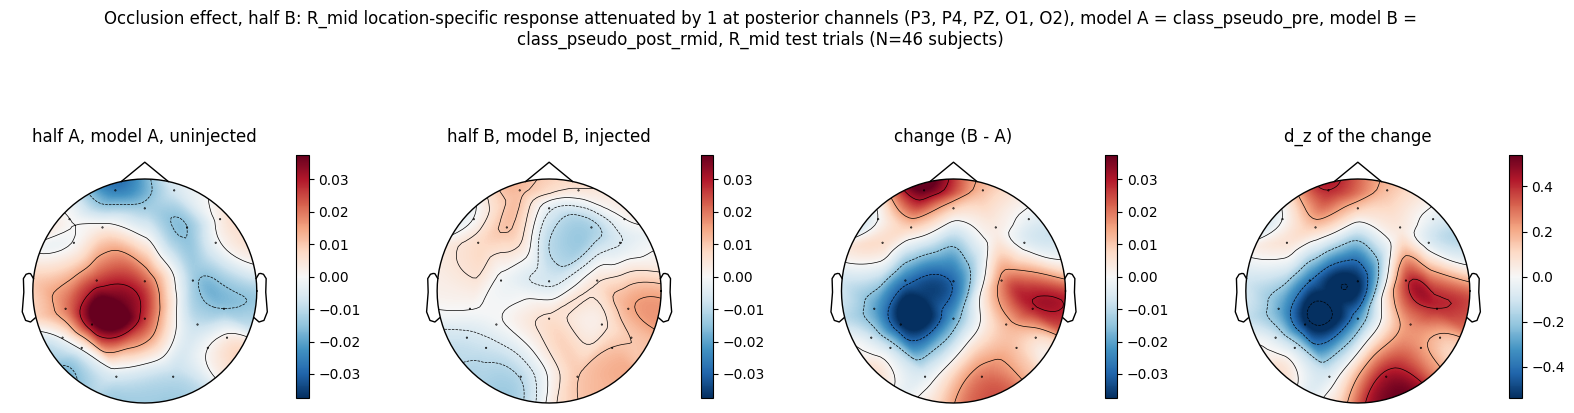

Occlusion effect, half B: R_mid location-specific response attenuated by 1 at posterior channels (P3, P4, PZ, O1, O2), change (B - A):
  max: FP1 +0.0366, T4 +0.0285, O2 +0.0193
  min: P3 -0.0373, CZ -0.0286, C3 -0.0268


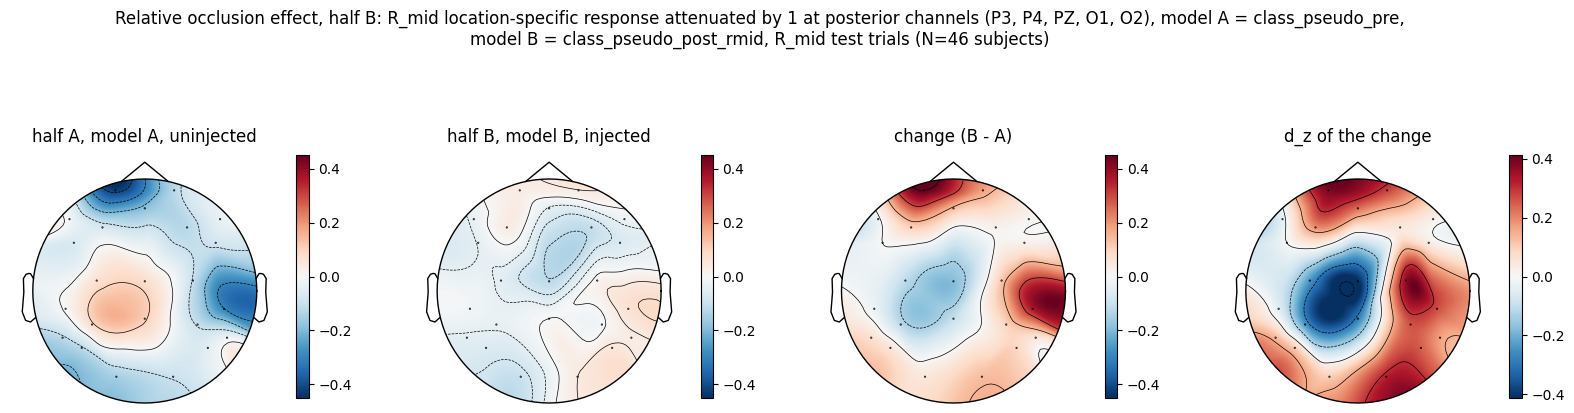

Relative occlusion effect, half B: R_mid location-specific response attenuated by 1 at posterior channels (P3, P4, PZ, O1, O2), change (B - A):
  max: FP1 +0.4504, T4 +0.3650, FP2 +0.1811
  min: CZ -0.1916, P3 -0.1236, C3 -0.1164
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
null test (no injection): p_true half A 0.1675 -> half B 0.1789, change (B - A) +0.0114 (t = 0.62, p = 0.537, N = 46)


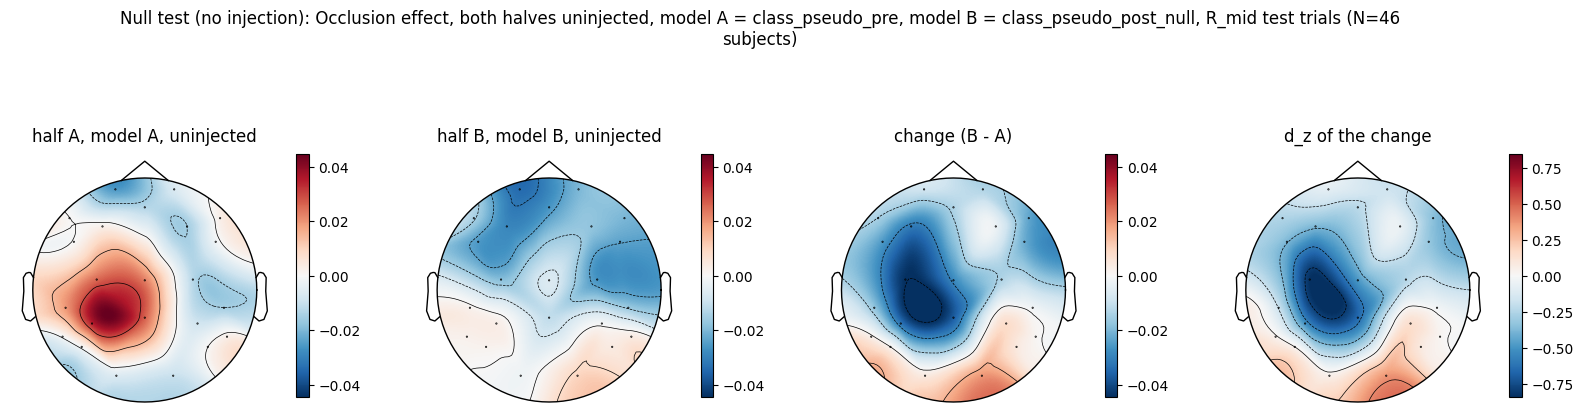

Null test (no injection): Occlusion effect, both halves uninjected, change (B - A):
  max: O2 +0.0188, P4 +0.0076, T6 +0.0048
  min: C3 -0.0445, PZ -0.0372, P3 -0.0334


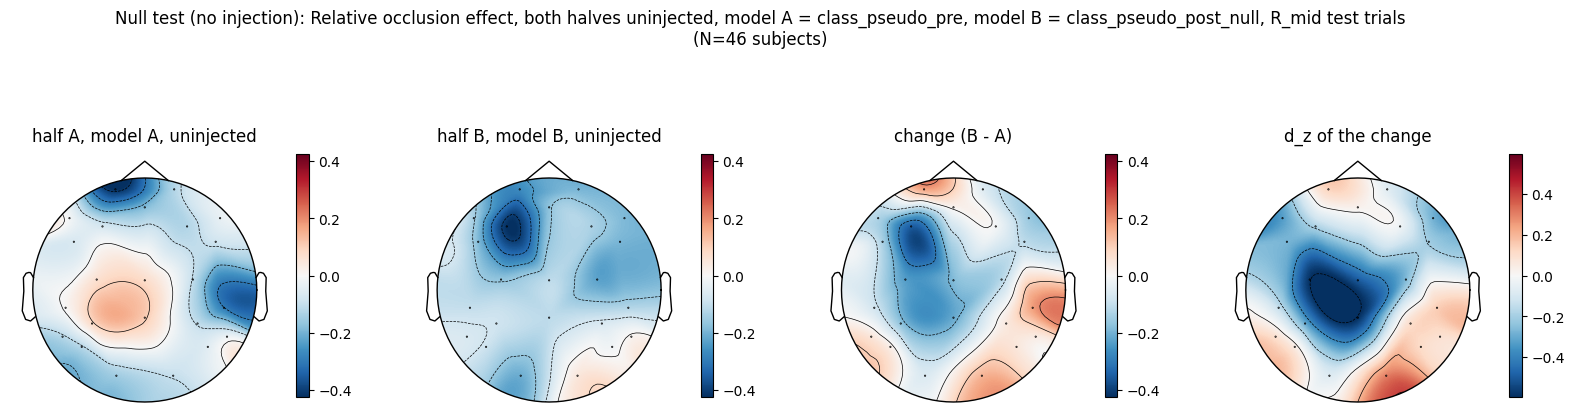

Null test (no injection): Relative occlusion effect, both halves uninjected, change (B - A):
  max: T4 +0.1715, FP1 +0.1599, O2 +0.1390
  min: F3 -0.3521, C3 -0.2360, PZ -0.2165
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
half B injected, attenuation 0.5: p_true half A 0.1675 -> half B 0.1347, change (B - A) -0.0328 (t = -2.40, p = 0.02046, N = 46)


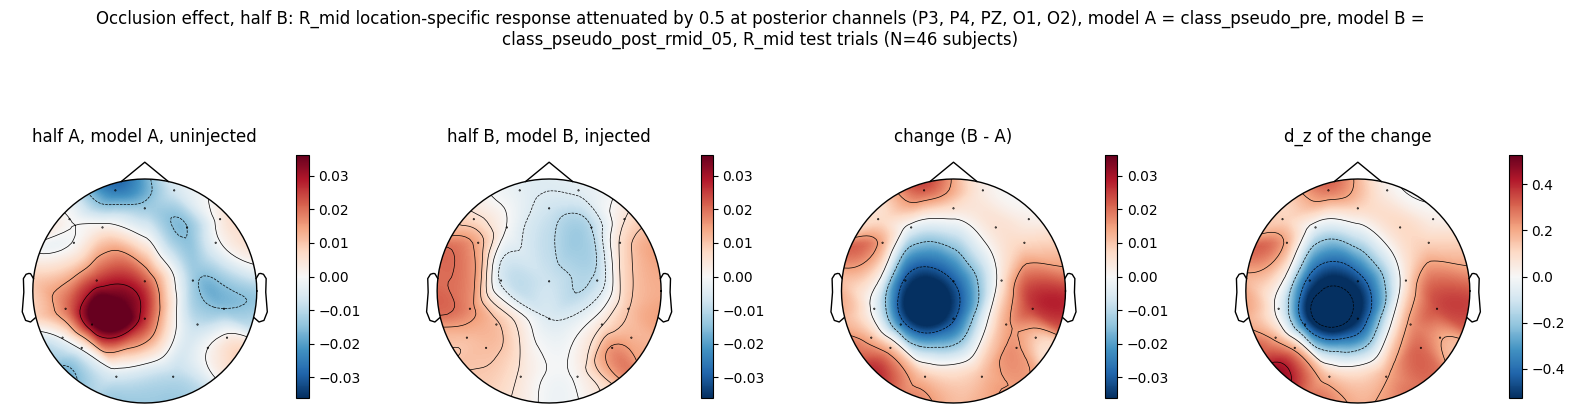

Occlusion effect, half B: R_mid location-specific response attenuated by 0.5 at posterior channels (P3, P4, PZ, O1, O2), change (B - A):
  max: T4 +0.0247, FP1 +0.0216, T6 +0.0160
  min: C3 -0.0315, PZ -0.0311, CZ -0.0298


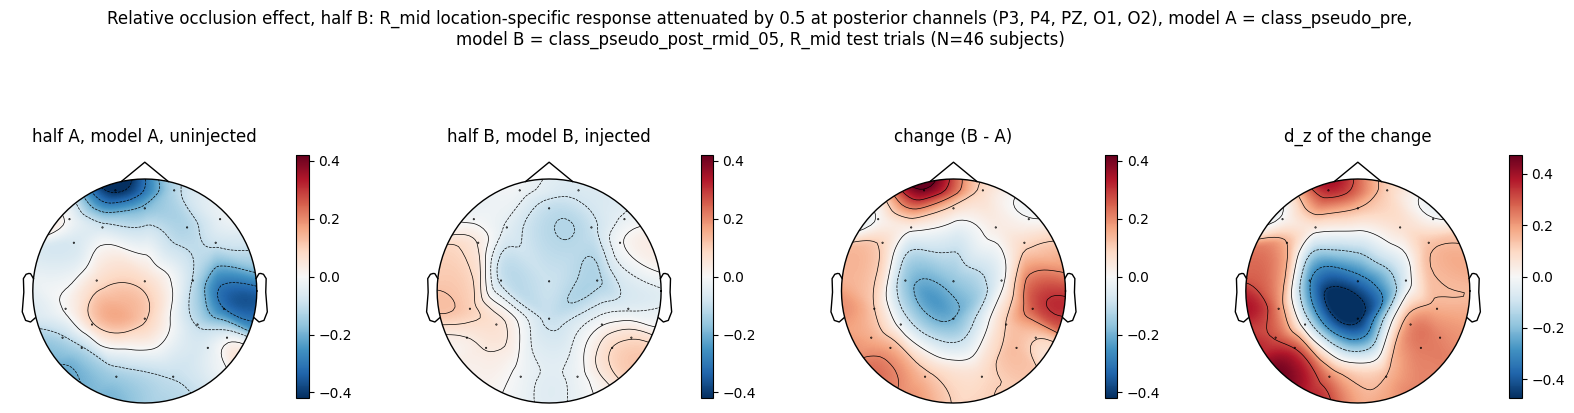

Relative occlusion effect, half B: R_mid location-specific response attenuated by 0.5 at posterior channels (P3, P4, PZ, O1, O2), change (B - A):
  max: FP1 +0.3897, T4 +0.2510, T5 +0.1510
  min: PZ -0.1992, CZ -0.1650, C3 -0.1584


In [30]:
import json

pseudo_pre_model = "class_pseudo_pre"  # run_general_finetune.py --pseudo_session pre
pseudo_post_models = {"planted": "class_pseudo_post_rmid", "null": "class_pseudo_post_null", "planted_05": "class_pseudo_post_rmid_05"}  # --pseudo_session post (with / without plant)
pseudo_condition = "right_2"  # --plant_condition of the planted model
# the plant of every pseudo post model as trained (--plant_condition, --plant_attenuation), used where the run's
# metadata.json isn't available; the metadata wins where it is
pseudo_post_plants = {"class_pseudo_post_rmid": {"plant_condition": "right_2", "plant_attenuation": 1.0},
                      "class_pseudo_post_null": {"plant_condition": None, "plant_attenuation": None},
                      "class_pseudo_post_rmid_05": {"plant_condition": "right_2", "plant_attenuation": 0.5}}

planted_class = settings.CONDITION_CLASS_IDS[pseudo_condition]
planted_label = settings.LOCATION_CLASSES[pseudo_condition]["label"]
pre_df = load_filtered_merged(pseudo_pre_model, mode="channel", sessions=("baseline",))
pre_df = pre_df[pre_df["label"] == planted_class]
for pair, post_model in pseudo_post_models.items():
    meta_path = settings.FINETUNE_OUTPUT_DIR / post_model / "metadata.json"
    plant = json.load(open(meta_path, encoding="utf-8"))["hyperparameters"] if meta_path.exists() else pseudo_post_plants[post_model]
    post_df = load_filtered_merged(post_model, mode="channel", sessions=("postpatch",))
    pair_df = pd.concat([pre_df, post_df[post_df["label"] == planted_class]], ignore_index=True)
    pair_df["p_true"] = pair_df["occlusion_effect"] + pair_df["occluded_p_true"]

    # the trial-level true-class probability per subject (different trials in the two halves, paired by subject)
    subject_p_true = pair_df.groupby(["session", "subject"])["p_true"].mean().unstack("session").dropna()
    change = subject_p_true["postpatch"] - subject_p_true["baseline"]
    test = ttest_1samp(change, 0)
    # half A (pseudo pre) with model A in the first slot, half B (pseudo post) with model B in the second: change = B - A
    if plant.get("plant_condition") is None:
        what, title_end = "null test (no injection)", "both halves uninjected"
        labels = ("half A, model A, uninjected", "half B, model B, uninjected")
    else:
        what = f"half B injected, attenuation {plant['plant_attenuation']:g}"
        title_end = (f"half B: {planted_label} location-specific response attenuated by {plant['plant_attenuation']:g} at "
                     f"posterior channels ({', '.join(settings.POSTERIOR_CHANNELS)})")
        labels = ("half A, model A, uninjected", "half B, model B, injected")
    print(f"{what}: p_true half A {subject_p_true['baseline'].mean():.4f} -> half B {subject_p_true['postpatch'].mean():.4f}, "
          f"change (B - A) {change.mean():+.4f} (t = {test.statistic:.2f}, p = {test.pvalue:.4g}, N = {len(change)})")
    null_prefix = "Null test (no injection): " if plant.get("plant_condition") is None else ""

    model_label = f"model A = {pseudo_pre_model}, model B = {post_model}, {planted_label} test trials"
    file_name = f"pseudo_{pair}_{post_model}_{planted_label}"
    channel_change_topomaps(pair_df, f"{null_prefix}Occlusion effect, {title_end}", model_label=model_label, session_labels=labels,
                            change_label="change (B - A)", save_dir=plot_dirs["labram_within"], default_name=f"{file_name}_occlusion")
    channel_change_topomaps(pair_df, f"{null_prefix}Relative occlusion effect, {title_end}", relative=True, model_label=model_label,
                            session_labels=labels, change_label="change (B - A)", save_dir=plot_dirs["labram_within"],
                            default_name=f"{file_name}_relative_occlusion")
